https://www.kaggle.com/competitions/brist1d/data

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from datetime import timedelta
from pandas.api.types import CategoricalDtype

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Загрузка данных

In [4]:
# чтение данных из файла
csv_file_path = dir_path + 'train.csv'
train_data = pd.read_csv(csv_file_path, index_col='id')

/tmp/ipython-input-3452154000.py:3: DtypeWarning: Columns (435,436,437,438,439,440,441,442,443,444,445,446,447,448,449,450,451,452,453,454,455,456,457,458,459,460,461,462,463,464,465,466,467,468,469,470,471,472,473,474,475,476,477,478,479,480,481,482,483,484,485,486,487,488,489,490,491,492,493,494,495,496,497,498,499,500,501,502,503,504,505,506) have mixed types. Specify dtype option on import or set low_memory=False.
  train_data = pd.read_csv(csv_file_path, index_col='id')


In [5]:
# размер датафрейма
train_data.shape

(177024, 507)

In [6]:
train_data.head()

,p_num,time,bg-5:55,bg-5:50,bg-5:45,bg-5:40,bg-5:35,bg-5:30,bg-5:25,bg-5:20,...,activity-0:40,activity-0:35,activity-0:30,activity-0:25,activity-0:20,activity-0:15,activity-0:10,activity-0:05,activity-0:00,bg+1:00
id,,,,,,,,,,,,,,,,,,,,,
p01_0,p01,06:10:00,NaN,NaN,9.6,NaN,NaN,9.7,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.4
p01_1,p01,06:25:00,NaN,NaN,9.7,NaN,NaN,9.2,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.8
p01_2,p01,06:40:00,NaN,NaN,9.2,NaN,NaN,8.7,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.5
p01_3,p01,06:55:00,NaN,NaN,8.7,NaN,NaN,8.4,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.8
p01_4,p01,07:10:00,NaN,NaN,8.4,NaN,NaN,8.1,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.7


In [7]:
# количество пропущенных значений в 'bg-0:00'
train_data['bg-0:00'].isna().sum()

np.int64(2696)

In [8]:
# информация о датафрейме
train_data.info(max_cols=600)

<class 'pandas.core.frame.DataFrame'>
Index: 177024 entries, p01_0 to p12_25298
Data columns (total 507 columns):
 #    Column         Non-Null Count   Dtype  
---   ------         --------------   -----  
 0    p_num          177024 non-null  object 
 1    time           177024 non-null  object 
 2    bg-5:55        149770 non-null  float64
 3    bg-5:50        158533 non-null  float64
 4    bg-5:45        163364 non-null  float64
 5    bg-5:40        149766 non-null  float64
 6    bg-5:35        158254 non-null  float64
 7    bg-5:30        163770 non-null  float64
 8    bg-5:25        149763 non-null  float64
 9    bg-5:20        157973 non-null  float64
 10   bg-5:15        164174 non-null  float64
 11   bg-5:10        149771 non-null  float64
 12   bg-5:05        157677 non-null  float64
 13   bg-5:00        164585 non-null  float64
 14   bg-4:55        149780 non-null  float64
 15   bg-4:50        157381 non-null  float64
 16   bg-4:45        164995 non-null  float64
 17   bg-4:4

In [9]:
# список всех столбцов
train_data.columns.to_list()

['p_num',
 'time',
 'bg-5:55',
 'bg-5:50',
 'bg-5:45',
 'bg-5:40',
 'bg-5:35',
 'bg-5:30',
 'bg-5:25',
 'bg-5:20',
 'bg-5:15',
 'bg-5:10',
 'bg-5:05',
 'bg-5:00',
 'bg-4:55',
 'bg-4:50',
 'bg-4:45',
 'bg-4:40',
 'bg-4:35',
 'bg-4:30',
 'bg-4:25',
 'bg-4:20',
 'bg-4:15',
 'bg-4:10',
 'bg-4:05',
 'bg-4:00',
 'bg-3:55',
 'bg-3:50',
 'bg-3:45',
 'bg-3:40',
 'bg-3:35',
 'bg-3:30',
 'bg-3:25',
 'bg-3:20',
 'bg-3:15',
 'bg-3:10',
 'bg-3:05',
 'bg-3:00',
 'bg-2:55',
 'bg-2:50',
 'bg-2:45',
 'bg-2:40',
 'bg-2:35',
 'bg-2:30',
 'bg-2:25',
 'bg-2:20',
 'bg-2:15',
 'bg-2:10',
 'bg-2:05',
 'bg-2:00',
 'bg-1:55',
 'bg-1:50',
 'bg-1:45',
 'bg-1:40',
 'bg-1:35',
 'bg-1:30',
 'bg-1:25',
 'bg-1:20',
 'bg-1:15',
 'bg-1:10',
 'bg-1:05',
 'bg-1:00',
 'bg-0:55',
 'bg-0:50',
 'bg-0:45',
 'bg-0:40',
 'bg-0:35',
 'bg-0:30',
 'bg-0:25',
 'bg-0:20',
 'bg-0:15',
 'bg-0:10',
 'bg-0:05',
 'bg-0:00',
 'insulin-5:55',
 'insulin-5:50',
 'insulin-5:45',
 'insulin-5:40',
 'insulin-5:35',
 'insulin-5:30',
 'insulin-5:25'

In [10]:
# имеются ли дубликаты?
train_data.duplicated().sum()

np.int64(0)

In [11]:
# количество пропущенных значений в каждом столбце
with pd.option_context("display.max_rows", 1000):
    display(train_data.isna().sum())

,0
p_num,0
time,0
bg-5:55,27254
bg-5:50,18491
bg-5:45,13660
bg-5:40,27258
bg-5:35,18770
bg-5:30,13254
bg-5:25,27261
bg-5:20,19051


In [12]:
# статистика по каждому столбцу
with pd.option_context("display.max_rows", 1000):
    display(train_data.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
p_num,177024,9,p03,26028,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time,177024,288,11:55:00,640,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bg-5:55,149770.0,NaN,NaN,NaN,8.211018,2.852188,2.2,6.1,7.6,9.8,22.2
bg-5:50,158533.0,NaN,NaN,NaN,8.230449,2.913438,2.2,6.1,7.6,9.8,25.1
bg-5:45,163364.0,NaN,NaN,NaN,8.253291,2.945594,2.2,6.1,7.7,9.8,27.8
bg-5:40,149766.0,NaN,NaN,NaN,8.210988,2.85209,2.2,6.1,7.6,9.8,22.2
bg-5:35,158254.0,NaN,NaN,NaN,8.229649,2.911313,2.2,6.1,7.6,9.8,25.1
bg-5:30,163770.0,NaN,NaN,NaN,8.254083,2.947651,2.2,6.1,7.7,9.8,27.8
bg-5:25,149763.0,NaN,NaN,NaN,8.211049,2.852212,2.2,6.1,7.6,9.8,22.2
bg-5:20,157973.0,NaN,NaN,NaN,8.228888,2.909304,2.2,6.1,7.6,9.8,25.1


In [13]:
# преобразование типов данных в категориальный
train_data['p_num'] = train_data['p_num'].astype('category')

In [14]:
# переводим дату в формат "%H:%M:%S"
train_data.time = pd.to_datetime(train_data.time, format="%H:%M:%S")

### Пропущенные значения в уровне глюкозы

In [15]:
train_data['bg-0:00'].isna().sum()

np.int64(2696)

In [16]:
train_bg_isna = pd.concat([train_data[['p_num','time']], train_data.loc[:,'bg-5:55':'bg-0:00']], axis=1)
train_bg0_isna = train_bg_isna[train_bg_isna['bg-0:00'].isna()]

In [17]:
train_bg0_isna.shape[0]

2696

Text(0.5, 1.0, 'Количество пропущенных значений в "bg-0:00"')

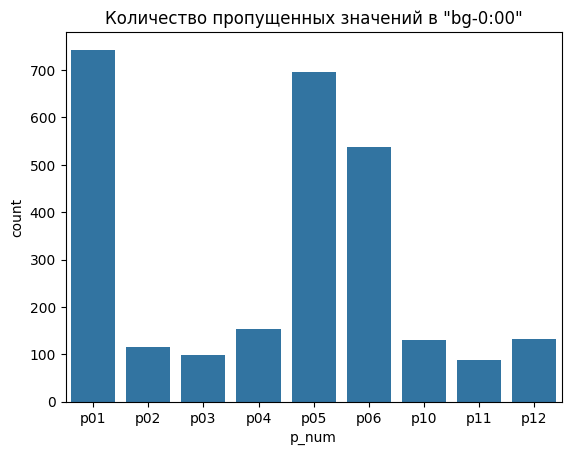

In [18]:
sns.countplot(x=train_bg0_isna['p_num'])
plt.title('Количество пропущенных значений в "bg-0:00"')

In [19]:
train_bg0_isna.groupby('p_num', observed=False)['time'].count()

,time
p_num,
p01,743
p02,115
p03,98
p04,154
p05,697
p06,538
p10,130
p11,89
p12,132


In [20]:
train_bg0_isna_more_15_min = train_bg0_isna[train_bg0_isna['bg-0:05'].isna()
                                            & train_bg0_isna['bg-0:10'].isna()
                                            & train_bg0_isna['bg-0:15'].isna()
                                            ]

In [21]:
train_bg0_isna_more_15_min.shape[0]

953

Text(0.5, 1.0, 'Количество пропущенных значений одновременно в столбцах с "bg-0:10" по "bg-0:00"')

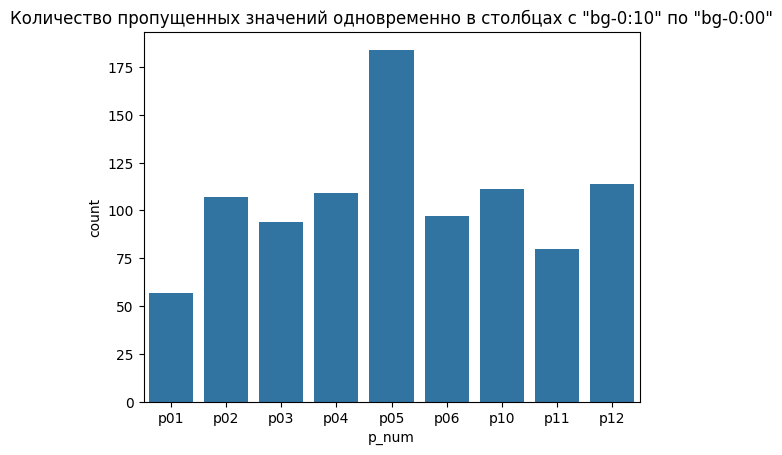

In [22]:
sns.countplot(x=train_bg0_isna_more_15_min['p_num'])
plt.title('Количество пропущенных значений одновременно в столбцах с "bg-0:10" по "bg-0:00"')

In [23]:
train_bg_isna_p05 = train_bg0_isna_more_15_min.groupby('p_num').get_group('p05')
train_bg_isna_p05

/tmp/ipython-input-372163613.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  train_bg_isna_p05 = train_bg0_isna_more_15_min.groupby('p_num').get_group('p05')


,p_num,time,bg-5:55,bg-5:50,bg-5:45,bg-5:40,bg-5:35,bg-5:30,bg-5:25,bg-5:20,...,bg-0:45,bg-0:40,bg-0:35,bg-0:30,bg-0:25,bg-0:20,bg-0:15,bg-0:10,bg-0:05,bg-0:00
id,,,,,,,,,,,,,,,,,,,,,
p05_77,p05,1900-01-01 04:10:00,10.8,NaN,NaN,10.9,NaN,NaN,11.3,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
p05_78,p05,1900-01-01 04:25:00,10.9,NaN,NaN,11.3,NaN,NaN,11.7,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
p05_79,p05,1900-01-01 04:40:00,11.3,NaN,NaN,11.7,NaN,NaN,12.7,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
p05_80,p05,1900-01-01 04:55:00,11.7,NaN,NaN,12.7,NaN,NaN,12.9,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
p05_147,p05,1900-01-01 23:20:00,NaN,13.8,NaN,NaN,13.7,NaN,NaN,13.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
p05_7226,p05,1900-01-01 20:15:00,NaN,9.7,NaN,NaN,9.2,NaN,NaN,8.4,...,7.4,NaN,NaN,7.3,NaN,NaN,NaN,NaN,NaN,NaN
p05_7980,p05,1900-01-01 18:55:00,9.8,NaN,NaN,9.7,NaN,NaN,9.4,NaN,...,NaN,10.6,NaN,NaN,10.3,NaN,NaN,NaN,NaN,NaN
p05_7981,p05,1900-01-01 19:10:00,9.7,NaN,NaN,9.4,NaN,NaN,9.8,NaN,...,NaN,10.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# train с базовыми признаками

In [24]:
train_with_basic_features = train_data[['p_num',
                                       'time',
                                       'bg-0:00',
                                       'insulin-0:00',
                                       'carbs-0:00',
                                       'hr-0:00',
                                       'steps-0:00',
                                       'cals-0:00',
                                       'activity-0:00',
                                       'bg+1:00'
                                       ]].copy()

In [25]:
train_with_basic_features.describe(include='all')

,p_num,time,bg-0:00,insulin-0:00,carbs-0:00,hr-0:00,steps-0:00,cals-0:00,activity-0:00,bg+1:00
count,177024,177024,174328.000000,167649.000000,2583.000000,125890.000000,81940.000000,141767.000000,2737,177024.000000
unique,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22,NaN
top,p03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Walk,NaN
freq,26028,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1973,NaN
mean,NaN,1900-01-01 11:56:31.746882048,8.277378,0.204064,48.018970,79.335216,53.052685,9.368960,NaN,8.277045
min,NaN,1900-01-01 00:00:00,2.200000,-0.307800,1.000000,39.000000,0.000000,0.030000,NaN,2.200000
25%,NaN,1900-01-01 06:00:00,6.100000,0.041700,24.000000,64.800000,0.000000,5.600000,NaN,6.100000
50%,NaN,1900-01-01 11:55:00,7.700000,0.075000,40.000000,77.500000,8.000000,6.180000,NaN,7.700000
75%,NaN,1900-01-01 17:50:00,9.900000,0.108300,65.000000,90.000000,56.000000,9.060000,NaN,9.900000
max,NaN,1900-01-01 23:55:00,27.800000,46.311000,852.000000,185.300000,1359.000000,116.100000,NaN,27.800000


###steps

Определим, возможно ли человеку пройти 1359 шагов за 5 минут.

Рассчитаем среднюю скорость ходьбы.

Средняя длина шага взрослого человека составляет примерно 75 см.

Тогда общая пройденная дистанция составит:
$1359\ шагов ⋅ 0.75\ м/шаг = 1019.25\ м = 1.01925\ км$

Расчет средней скорости:

$V = \frac{S}{T} = \frac{1.01925\ \text{км}}{5 / 60 \ \text{ч}} = 12.231 \ \text{км/ч}$

Полученная средняя скорость (12.231 км/ч) превышает обычную пешеходную скорость (~5–6 км/ч), однако такая скорость достижима при беге трусцой.

###insulin

In [26]:
train_with_basic_features[train_with_basic_features['insulin-0:00']<0]

,p_num,time,bg-0:00,insulin-0:00,carbs-0:00,hr-0:00,steps-0:00,cals-0:00,activity-0:00,bg+1:00
id,,,,,,,,,,
p12_23375,p12,1900-01-01 02:50:00,10.0,-0.3078,NaN,73.0,0.0,6.75,NaN,11.6
p12_24717,p12,1900-01-01 23:30:00,9.8,-0.0590,NaN,99.6,9.0,12.30,NaN,8.9


In [27]:
with pd.option_context("display.max_columns", 1000):
    display(train_data[train_data['insulin-0:00']<0])

,p_num,time,bg-5:55,bg-5:50,bg-5:45,bg-5:40,bg-5:35,bg-5:30,bg-5:25,bg-5:20,bg-5:15,bg-5:10,bg-5:05,bg-5:00,bg-4:55,bg-4:50,bg-4:45,bg-4:40,bg-4:35,bg-4:30,bg-4:25,bg-4:20,bg-4:15,bg-4:10,bg-4:05,bg-4:00,bg-3:55,bg-3:50,bg-3:45,bg-3:40,bg-3:35,bg-3:30,bg-3:25,bg-3:20,bg-3:15,bg-3:10,bg-3:05,bg-3:00,bg-2:55,bg-2:50,bg-2:45,bg-2:40,bg-2:35,bg-2:30,bg-2:25,bg-2:20,bg-2:15,bg-2:10,bg-2:05,bg-2:00,bg-1:55,bg-1:50,bg-1:45,bg-1:40,bg-1:35,bg-1:30,bg-1:25,bg-1:20,bg-1:15,bg-1:10,bg-1:05,bg-1:00,bg-0:55,bg-0:50,bg-0:45,bg-0:40,bg-0:35,bg-0:30,bg-0:25,bg-0:20,bg-0:15,bg-0:10,bg-0:05,bg-0:00,insulin-5:55,insulin-5:50,insulin-5:45,insulin-5:40,insulin-5:35,insulin-5:30,insulin-5:25,insulin-5:20,insulin-5:15,insulin-5:10,insulin-5:05,insulin-5:00,insulin-4:55,insulin-4:50,insulin-4:45,insulin-4:40,insulin-4:35,insulin-4:30,insulin-4:25,insulin-4:20,insulin-4:15,insulin-4:10,insulin-4:05,insulin-4:00,insulin-3:55,insulin-3:50,insulin-3:45,insulin-3:40,insulin-3:35,insulin-3:30,insulin-3:25,insulin-3:20,insulin-3:15,insulin-3:10,insulin-3:05,insulin-3:00,insulin-2:55,insulin-2:50,insulin-2:45,insulin-2:40,insulin-2:35,insulin-2:30,insulin-2:25,insulin-2:20,insulin-2:15,insulin-2:10,insulin-2:05,insulin-2:00,insulin-1:55,insulin-1:50,insulin-1:45,insulin-1:40,insulin-1:35,insulin-1:30,insulin-1:25,insulin-1:20,insulin-1:15,insulin-1:10,insulin-1:05,insulin-1:00,insulin-0:55,insulin-0:50,insulin-0:45,insulin-0:40,insulin-0:35,insulin-0:30,insulin-0:25,insulin-0:20,insulin-0:15,insulin-0:10,insulin-0:05,insulin-0:00,carbs-5:55,carbs-5:50,carbs-5:45,carbs-5:40,carbs-5:35,carbs-5:30,carbs-5:25,carbs-5:20,carbs-5:15,carbs-5:10,carbs-5:05,carbs-5:00,carbs-4:55,carbs-4:50,carbs-4:45,carbs-4:40,carbs-4:35,carbs-4:30,carbs-4:25,carbs-4:20,carbs-4:15,carbs-4:10,carbs-4:05,carbs-4:00,carbs-3:55,carbs-3:50,carbs-3:45,carbs-3:40,carbs-3:35,carbs-3:30,carbs-3:25,carbs-3:20,carbs-3:15,carbs-3:10,carbs-3:05,carbs-3:00,carbs-2:55,carbs-2:50,carbs-2:45,carbs-2:40,carbs-2:35,carbs-2:30,carbs-2:25,carbs-2:20,carbs-2:15,carbs-2:10,carbs-2:05,carbs-2:00,carbs-1:55,carbs-1:50,carbs-1:45,carbs-1:40,carbs-1:35,carbs-1:30,carbs-1:25,carbs-1:20,carbs-1:15,carbs-1:10,carbs-1:05,carbs-1:00,carbs-0:55,carbs-0:50,carbs-0:45,carbs-0:40,carbs-0:35,carbs-0:30,carbs-0:25,carbs-0:20,carbs-0:15,carbs-0:10,carbs-0:05,carbs-0:00,hr-5:55,hr-5:50,hr-5:45,hr-5:40,hr-5:35,hr-5:30,hr-5:25,hr-5:20,hr-5:15,hr-5:10,hr-5:05,hr-5:00,hr-4:55,hr-4:50,hr-4:45,hr-4:40,hr-4:35,hr-4:30,hr-4:25,hr-4:20,hr-4:15,hr-4:10,hr-4:05,hr-4:00,hr-3:55,hr-3:50,hr-3:45,hr-3:40,hr-3:35,hr-3:30,hr-3:25,hr-3:20,hr-3:15,hr-3:10,hr-3:05,hr-3:00,hr-2:55,hr-2:50,hr-2:45,hr-2:40,hr-2:35,hr-2:30,hr-2:25,hr-2:20,hr-2:15,hr-2:10,hr-2:05,hr-2:00,hr-1:55,hr-1:50,hr-1:45,hr-1:40,hr-1:35,hr-1:30,hr-1:25,hr-1:20,hr-1:15,hr-1:10,hr-1:05,hr-1:00,hr-0:55,hr-0:50,hr-0:45,hr-0:40,hr-0:35,hr-0:30,hr-0:25,hr-0:20,hr-0:15,hr-0:10,hr-0:05,hr-0:00,steps-5:55,steps-5:50,steps-5:45,steps-5:40,steps-5:35,steps-5:30,steps-5:25,steps-5:20,steps-5:15,steps-5:10,steps-5:05,steps-5:00,steps-4:55,steps-4:50,steps-4:45,steps-4:40,steps-4:35,steps-4:30,steps-4:25,steps-4:20,steps-4:15,steps-4:10,steps-4:05,steps-4:00,steps-3:55,steps-3:50,steps-3:45,steps-3:40,steps-3:35,steps-3:30,steps-3:25,steps-3:20,steps-3:15,steps-3:10,steps-3:05,steps-3:00,steps-2:55,steps-2:50,steps-2:45,steps-2:40,steps-2:35,steps-2:30,steps-2:25,steps-2:20,steps-2:15,steps-2:10,steps-2:05,steps-2:00,steps-1:55,steps-1:50,steps-1:45,steps-1:40,steps-1:35,steps-1:30,steps-1:25,steps-1:20,steps-1:15,steps-1:10,steps-1:05,steps-1:00,steps-0:55,steps-0:50,steps-0:45,steps-0:40,steps-0:35,steps-0:30,steps-0:25,steps-0:20,steps-0:15,steps-0:10,steps-0:05,steps-0:00,cals-5:55,cals-5:50,cals-5:45,cals-5:40,cals-5:35,cals-5:30,cals-5:25,cals-5:20,cals-5:15,cals-5:10,cals-5:05,cals-5:00,cals-4:55,cals-4:50,cals-4:45,cals-4:40,cals-4:35,cals-4:30,cals-4:25,cals-4:20,cals-4:15,cals-4:10,cals-4:05,cals-4:00,cals-3:55,cals-3:50,cals-3:45,cals-3:40,cals-3:35,cals-3:30,cals-3:25,cals-3

**Инсулин не может быть отрицательным. Убираем данную аномалию, заменяя на положительное значение.**

In [28]:
train_data.loc[:,'insulin-5:55':'insulin-0:00'] = train_data.loc[:,'insulin-5:55':'insulin-0:00'].abs()

In [29]:
train_with_basic_features.loc[:,'insulin-0:00'] = train_with_basic_features.loc[:,'insulin-0:00'].abs()

Text(0.5, 1.0, 'KDE (плотность вероятности) инсулина')

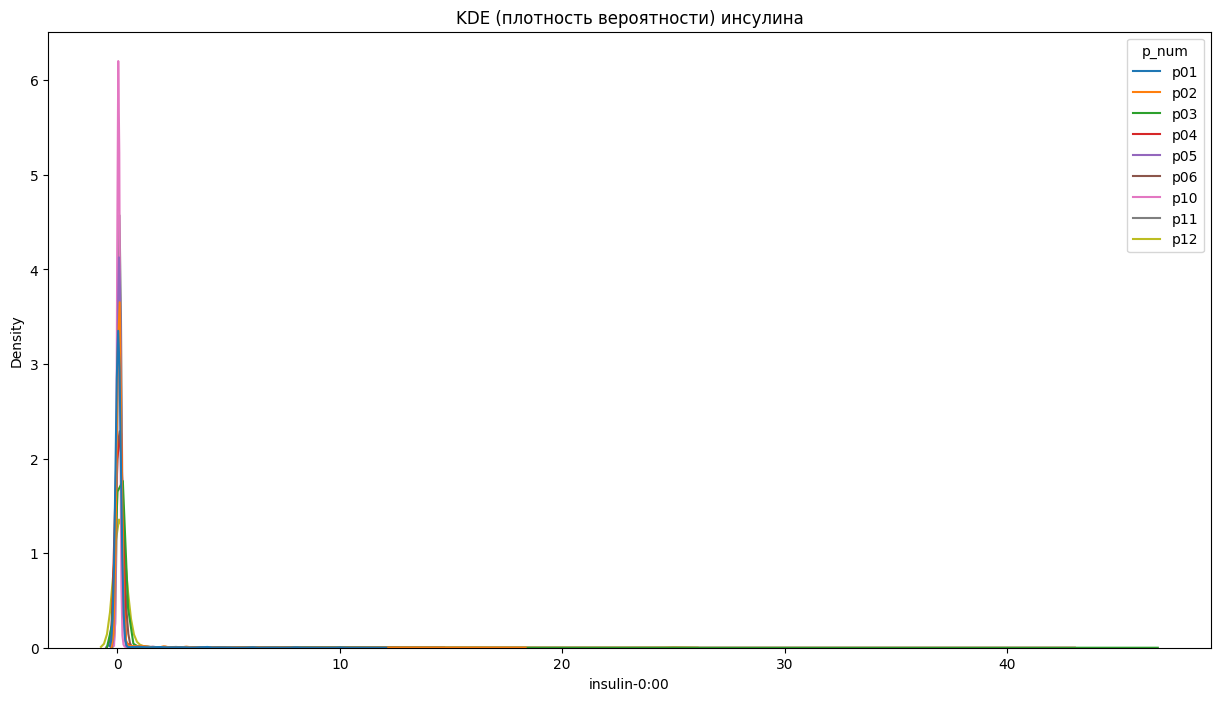

In [30]:
plt.figure(figsize=(15, 8))
sns.kdeplot(data=train_with_basic_features, x='insulin-0:00', hue='p_num', common_norm=False)
plt.title('KDE (плотность вероятности) инсулина')

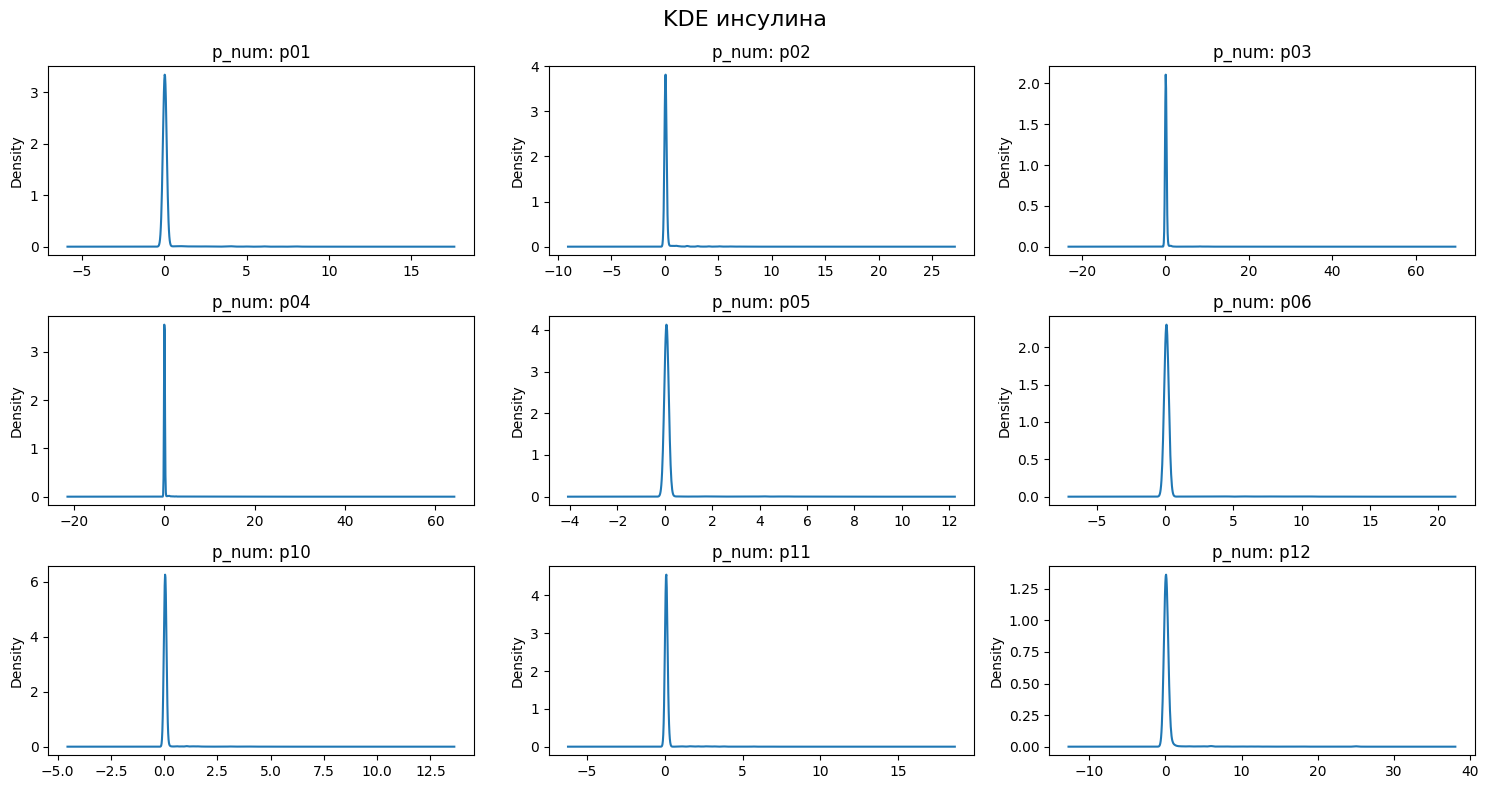

In [31]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 8))
fig.suptitle('KDE инсулина', fontsize=16)
# Группируем данные по 'p_num' и строим KDE на отдельных подграфиках
for i, (p_num, group) in enumerate(train_with_basic_features.groupby('p_num', observed=True)):
    ax = axes.flatten()[i]
    group['insulin-0:00'].plot(kind='kde', ax=ax, title=f'p_num: {p_num}')

plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'boxplot инсулина')

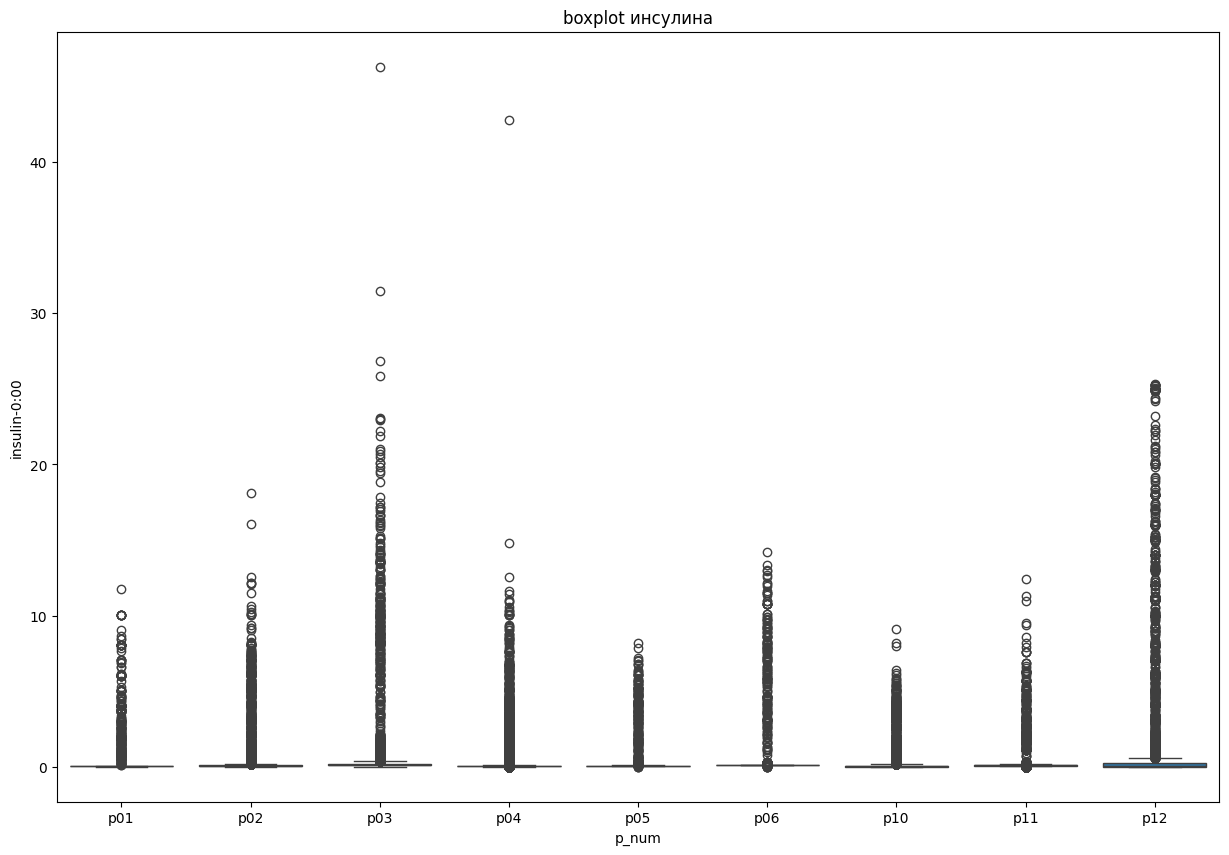

In [32]:
plt.figure(figsize=(15, 10))
sns.boxplot(data=train_with_basic_features, y='insulin-0:00', x='p_num')
plt.title('boxplot инсулина')

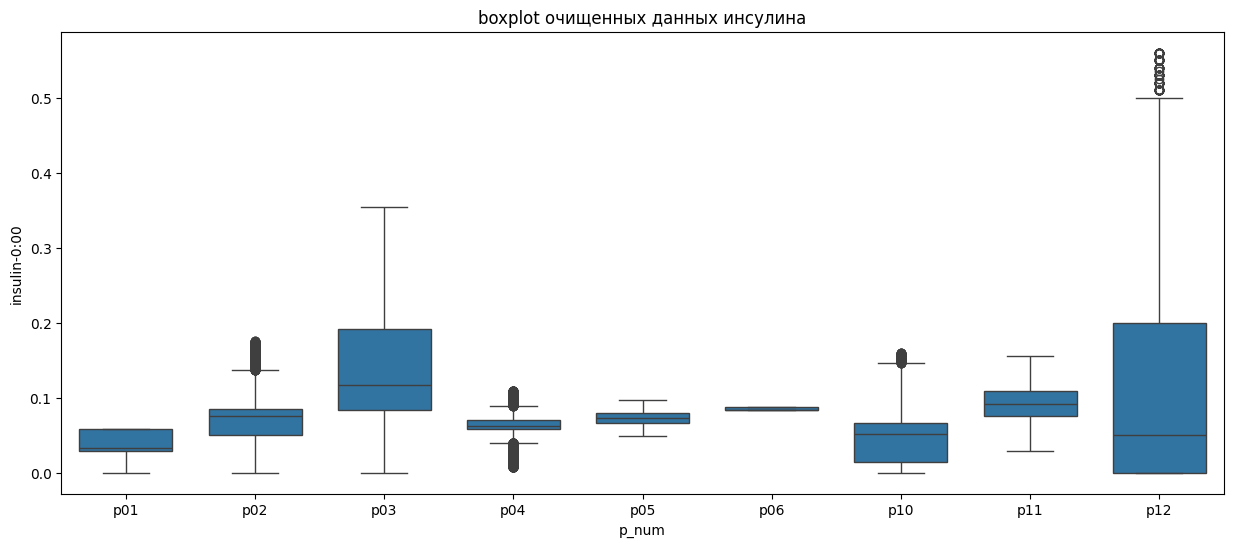

In [33]:
# Функция для удаления выбросов
def remove_outliers(group):
    Q1 = group['insulin-0:00'].quantile(0.25)
    Q3 = group['insulin-0:00'].quantile(0.75)
    IQR = Q3 - Q1
    return group[~((group['insulin-0:00'] < (Q1 - 1.5 * IQR)) | (group['insulin-0:00'] > (Q3 + 1.5 * IQR)))]

train_insulin_cleaned = train_with_basic_features.groupby('p_num', observed=False).apply(remove_outliers, include_groups=False)

# Построение боксплота для очищенных данных
plt.figure(figsize=(15, 6))
sns.boxplot(data=train_insulin_cleaned, y='insulin-0:00', x='p_num', gap=.1)
plt.title('boxplot очищенных данных инсулина')
plt.show()

###carbs

Text(0.5, 1.0, 'boxplot количества углеводов')

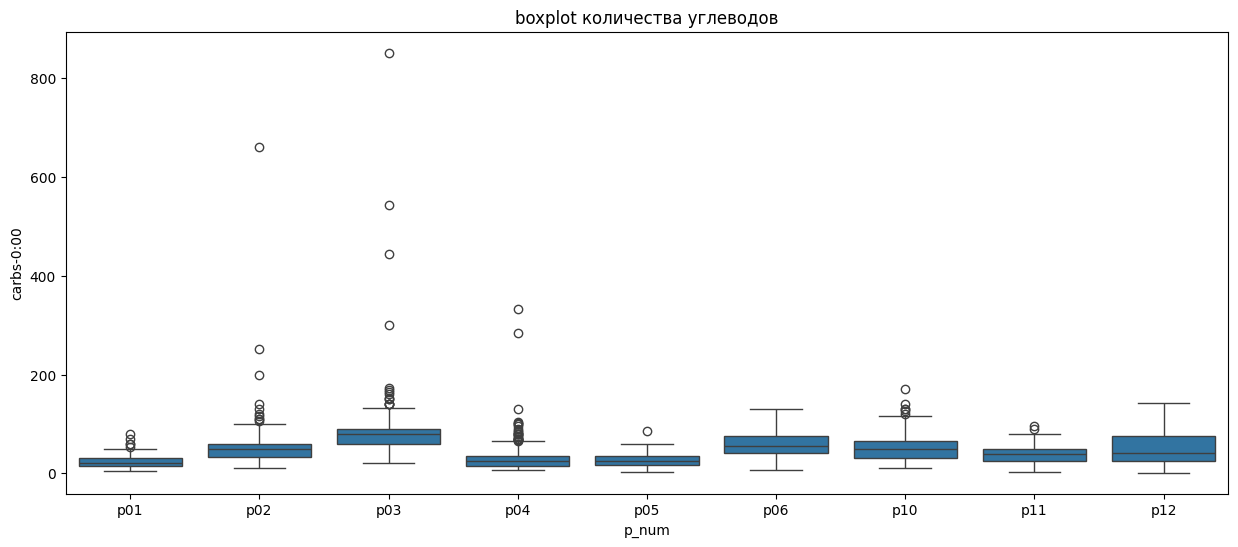

In [34]:
plt.figure(figsize=(15, 6))
sns.boxplot(data=train_with_basic_features, y='carbs-0:00', x='p_num')
plt.title('boxplot количества углеводов')

In [35]:
print('Записи с количеством углеводов >= 200')
train_with_basic_features[train_with_basic_features['carbs-0:00']>=200]

Записи с количеством углеводов >= 200


,p_num,time,bg-0:00,insulin-0:00,carbs-0:00,hr-0:00,steps-0:00,cals-0:00,activity-0:00,bg+1:00
id,,,,,,,,,,
p02_1248,p02,1900-01-01 18:35:00,13.0,12.0866,660.0,NaN,NaN,NaN,NaN,10.4
p02_13505,p02,1900-01-01 19:30:00,10.7,6.5139,252.0,106.4,100.0,5.42,NaN,8.7
p02_23467,p02,1900-01-01 20:25:00,10.4,6.8917,200.0,NaN,NaN,NaN,NaN,14.2
p03_959,p03,1900-01-01 14:00:00,5.5,46.3110,300.0,NaN,NaN,NaN,NaN,7.2
p03_8147,p03,1900-01-01 20:45:00,13.9,0.3902,544.0,81.2,12.0,6.85,NaN,8.8
p03_16581,p03,1900-01-01 13:00:00,10.8,0.2437,444.0,NaN,NaN,5.60,NaN,5.9
p03_16885,p03,1900-01-01 14:20:00,5.1,0.0483,852.0,82.9,0.0,5.96,NaN,3.5
p04_3168,p04,1900-01-01 08:50:00,7.4,0.0708,332.0,NaN,NaN,4.55,NaN,7.2
p04_21153,p04,1900-01-01 15:20:00,4.9,42.7800,285.0,88.3,0.0,7.92,NaN,11.4


### Количество записей для каждого пациента

<Axes: xlabel='p_num', ylabel='count'>

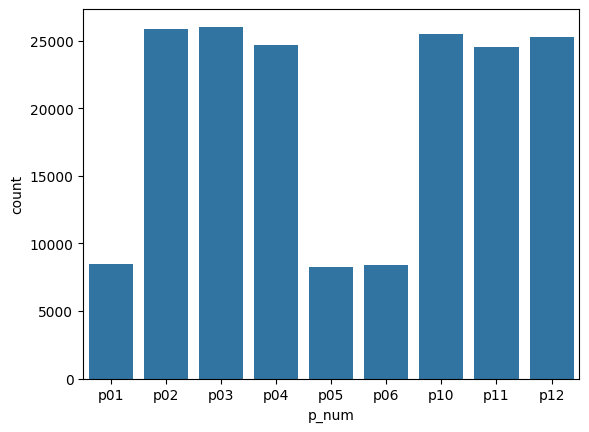

In [36]:
sns.countplot(x=train_with_basic_features['p_num'])

### Пропущенные значения

In [37]:
# количество не пропущенных значений по каждому пациенту в каждом столбце
with pd.option_context("display.max_columns", 1000):
  display(train_data.groupby('p_num').count())

/tmp/ipython-input-1419709272.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(train_data.groupby('p_num').count())


,time,bg-5:55,bg-5:50,bg-5:45,bg-5:40,bg-5:35,bg-5:30,bg-5:25,bg-5:20,bg-5:15,bg-5:10,bg-5:05,bg-5:00,bg-4:55,bg-4:50,bg-4:45,bg-4:40,bg-4:35,bg-4:30,bg-4:25,bg-4:20,bg-4:15,bg-4:10,bg-4:05,bg-4:00,bg-3:55,bg-3:50,bg-3:45,bg-3:40,bg-3:35,bg-3:30,bg-3:25,bg-3:20,bg-3:15,bg-3:10,bg-3:05,bg-3:00,bg-2:55,bg-2:50,bg-2:45,bg-2:40,bg-2:35,bg-2:30,bg-2:25,bg-2:20,bg-2:15,bg-2:10,bg-2:05,bg-2:00,bg-1:55,bg-1:50,bg-1:45,bg-1:40,bg-1:35,bg-1:30,bg-1:25,bg-1:20,bg-1:15,bg-1:10,bg-1:05,bg-1:00,bg-0:55,bg-0:50,bg-0:45,bg-0:40,bg-0:35,bg-0:30,bg-0:25,bg-0:20,bg-0:15,bg-0:10,bg-0:05,bg-0:00,insulin-5:55,insulin-5:50,insulin-5:45,insulin-5:40,insulin-5:35,insulin-5:30,insulin-5:25,insulin-5:20,insulin-5:15,insulin-5:10,insulin-5:05,insulin-5:00,insulin-4:55,insulin-4:50,insulin-4:45,insulin-4:40,insulin-4:35,insulin-4:30,insulin-4:25,insulin-4:20,insulin-4:15,insulin-4:10,insulin-4:05,insulin-4:00,insulin-3:55,insulin-3:50,insulin-3:45,insulin-3:40,insulin-3:35,insulin-3:30,insulin-3:25,insulin-3:20,insulin-3:15,insulin-3:10,insulin-3:05,insulin-3:00,insulin-2:55,insulin-2:50,insulin-2:45,insulin-2:40,insulin-2:35,insulin-2:30,insulin-2:25,insulin-2:20,insulin-2:15,insulin-2:10,insulin-2:05,insulin-2:00,insulin-1:55,insulin-1:50,insulin-1:45,insulin-1:40,insulin-1:35,insulin-1:30,insulin-1:25,insulin-1:20,insulin-1:15,insulin-1:10,insulin-1:05,insulin-1:00,insulin-0:55,insulin-0:50,insulin-0:45,insulin-0:40,insulin-0:35,insulin-0:30,insulin-0:25,insulin-0:20,insulin-0:15,insulin-0:10,insulin-0:05,insulin-0:00,carbs-5:55,carbs-5:50,carbs-5:45,carbs-5:40,carbs-5:35,carbs-5:30,carbs-5:25,carbs-5:20,carbs-5:15,carbs-5:10,carbs-5:05,carbs-5:00,carbs-4:55,carbs-4:50,carbs-4:45,carbs-4:40,carbs-4:35,carbs-4:30,carbs-4:25,carbs-4:20,carbs-4:15,carbs-4:10,carbs-4:05,carbs-4:00,carbs-3:55,carbs-3:50,carbs-3:45,carbs-3:40,carbs-3:35,carbs-3:30,carbs-3:25,carbs-3:20,carbs-3:15,carbs-3:10,carbs-3:05,carbs-3:00,carbs-2:55,carbs-2:50,carbs-2:45,carbs-2:40,carbs-2:35,carbs-2:30,carbs-2:25,carbs-2:20,carbs-2:15,carbs-2:10,carbs-2:05,carbs-2:00,carbs-1:55,carbs-1:50,carbs-1:45,carbs-1:40,carbs-1:35,carbs-1:30,carbs-1:25,carbs-1:20,carbs-1:15,carbs-1:10,carbs-1:05,carbs-1:00,carbs-0:55,carbs-0:50,carbs-0:45,carbs-0:40,carbs-0:35,carbs-0:30,carbs-0:25,carbs-0:20,carbs-0:15,carbs-0:10,carbs-0:05,carbs-0:00,hr-5:55,hr-5:50,hr-5:45,hr-5:40,hr-5:35,hr-5:30,hr-5:25,hr-5:20,hr-5:15,hr-5:10,hr-5:05,hr-5:00,hr-4:55,hr-4:50,hr-4:45,hr-4:40,hr-4:35,hr-4:30,hr-4:25,hr-4:20,hr-4:15,hr-4:10,hr-4:05,hr-4:00,hr-3:55,hr-3:50,hr-3:45,hr-3:40,hr-3:35,hr-3:30,hr-3:25,hr-3:20,hr-3:15,hr-3:10,hr-3:05,hr-3:00,hr-2:55,hr-2:50,hr-2:45,hr-2:40,hr-2:35,hr-2:30,hr-2:25,hr-2:20,hr-2:15,hr-2:10,hr-2:05,hr-2:00,hr-1:55,hr-1:50,hr-1:45,hr-1:40,hr-1:35,hr-1:30,hr-1:25,hr-1:20,hr-1:15,hr-1:10,hr-1:05,hr-1:00,hr-0:55,hr-0:50,hr-0:45,hr-0:40,hr-0:35,hr-0:30,hr-0:25,hr-0:20,hr-0:15,hr-0:10,hr-0:05,hr-0:00,steps-5:55,steps-5:50,steps-5:45,steps-5:40,steps-5:35,steps-5:30,steps-5:25,steps-5:20,steps-5:15,steps-5:10,steps-5:05,steps-5:00,steps-4:55,steps-4:50,steps-4:45,steps-4:40,steps-4:35,steps-4:30,steps-4:25,steps-4:20,steps-4:15,steps-4:10,steps-4:05,steps-4:00,steps-3:55,steps-3:50,steps-3:45,steps-3:40,steps-3:35,steps-3:30,steps-3:25,steps-3:20,steps-3:15,steps-3:10,steps-3:05,steps-3:00,steps-2:55,steps-2:50,steps-2:45,steps-2:40,steps-2:35,steps-2:30,steps-2:25,steps-2:20,steps-2:15,steps-2:10,steps-2:05,steps-2:00,steps-1:55,steps-1:50,steps-1:45,steps-1:40,steps-1:35,steps-1:30,steps-1:25,steps-1:20,steps-1:15,steps-1:10,steps-1:05,steps-1:00,steps-0:55,steps-0:50,steps-0:45,steps-0:40,steps-0:35,steps-0:30,steps-0:25,steps-0:20,steps-0:15,steps-0:10,steps-0:05,steps-0:00,cals-5:55,cals-5:50,cals-5:45,cals-5:40,cals-5:35,cals-5:30,cals-5:25,cals-5:20,cals-5:15,cals-5:10,cals-5:05,cals-5:00,cals-4:55,cals-4:50,cals-4:45,cals-4:40,cals-4:35,cals-4:30,cals-4:25,cals-4:20,cals-4:15,cals-4:10,cals-4:05,cals-4:00,cals-3:55,cals-3:50,cals-3:45,cals-3:40,cals-3:35,cals-3:30,cals-3:25,cals-3:20,ca

In [38]:
number_of_elements = train_data.size  # Количество элементов в датасете
train_len = train_data.shape[0]  # Всего записей (строк) в датасете

number_missing_values_in_column = train_data.isnull().sum()  # Количество NaN в колонке
number_missing_values = number_missing_values_in_column.sum()  # Количество всех NaN

print(f"Всего записей: {train_len}, всего значений: {number_of_elements}")
print(f"Пропущенных значений: {number_missing_values}, {round(((number_missing_values / number_of_elements) * 100), 2)} %")

percentage = train_data.isnull().mean() * 100
missing = pd.DataFrame({"Кол-во пропущенных значений": number_missing_values_in_column,
                        "Процент пропусков": round(percentage, 2)}).sort_values("Процент пропусков")
missing

Всего записей: 177024, всего значений: 89751168
Пропущенных значений: 40294794, 44.9 %


,Кол-во пропущенных значений,Процент пропусков
p_num,0,0.00
time,0,0.00
bg+1:00,0,0.00
bg-0:00,2696,1.52
bg-0:15,3272,1.85
...,...,...
carbs-2:10,174484,98.57
carbs-0:40,174488,98.57
carbs-5:15,174490,98.57
carbs-5:30,174490,98.57


###Корреляционная матрица (метод Спирмена)

Text(0.5, 1.0, 'Корреляционная матрица (метод Сирмена) для основных признаков')

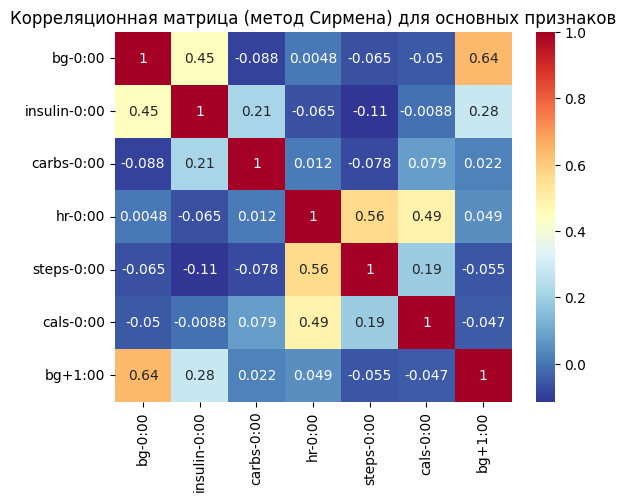

In [39]:
sns.heatmap(train_with_basic_features[['bg-0:00', 'insulin-0:00', 'carbs-0:00', 'hr-0:00', 'steps-0:00', 'cals-0:00', 'bg+1:00']].corr(method='spearman'),
            cmap="RdYlBu_r", annot=True)
plt.title('Корреляционная матрица (метод Сирмена) для основных признаков')

### Phik correlation — универсальная матрица связей

In [42]:
%%capture
#pip install phik

interval columns not set, guessing: ['bg-0:00', 'insulin-0:00', 'carbs-0:00', 'hr-0:00', 'steps-0:00', 'cals-0:00', 'bg+1:00']


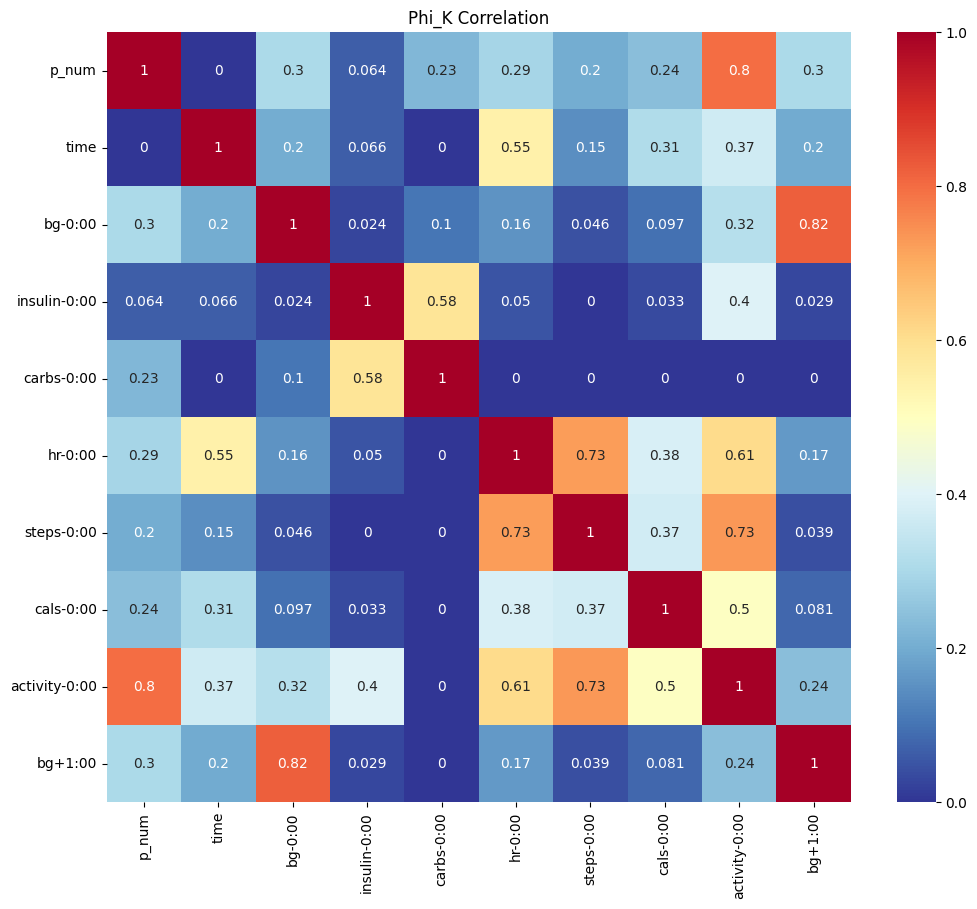

In [43]:
import phik

plt.figure(figsize=(12, 10))
sns.heatmap(train_with_basic_features.phik_matrix(), cmap="RdYlBu_r", annot=True)
plt.title('Phi_K Correlation');

interval columns not set, guessing: ['bg-0:15', 'bg-0:10', 'bg-0:05', 'bg-0:00', 'insulin-0:10', 'insulin-0:05', 'insulin-0:00', 'cals-0:10', 'cals-0:05', 'cals-0:00', 'steps-0:10', 'steps-0:05', 'steps-0:00', 'hr-0:10', 'hr-0:05', 'hr-0:00', 'carbs-0:10', 'carbs-0:05', 'carbs-0:00', 'bg+1:00']


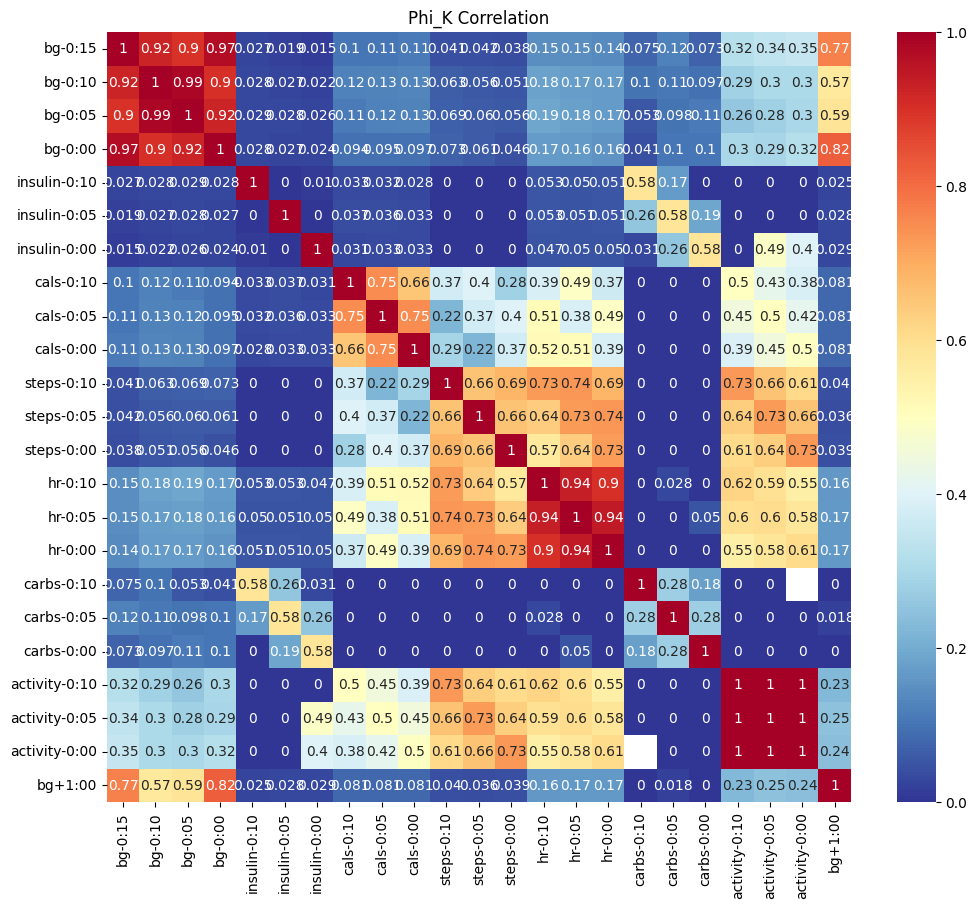

In [44]:
colums_corr = train_data[
    [
        "bg-0:15",
        "bg-0:10",
        "bg-0:05",
        "bg-0:00",
        "insulin-0:10",
        "insulin-0:05",
        "insulin-0:00",
        "cals-0:10",
        "cals-0:05",
        "cals-0:00",
        "steps-0:10",
        "steps-0:05",
        "steps-0:00",
        "hr-0:10",
        "hr-0:05",
        "hr-0:00",
        "carbs-0:10",
        "carbs-0:05",
        "carbs-0:00",
        'activity-0:10',
        'activity-0:05',
        'activity-0:00',
        "bg+1:00",
    ]
]

plt.figure(figsize=(12, 10))
sns.heatmap(colums_corr.phik_matrix(), cmap="RdYlBu_r", annot=True)
plt.title('Phi_K Correlation');

### Выявление пациентов с записями с 5 минутным и с 15 минутным интервалом

**Выполнено преобразование столбца time в объект типа datetime с форматом %H:%M:%S, а также устранены разрывы во временной последовательности при переходе через полночь путём добавления необходимого количества дней**

In [45]:
# устраним разрывы во временных рядах при переходе через полночь, делая временную шкалу непрерывной путем добавления необходимых дней
# Находим моменты, где происходит переход через полночь
train_with_basic_features['transitions_days'] = train_with_basic_features.groupby('p_num', observed=False)['time'].diff() < timedelta(0)
# Создаем массив дней для коррекции
correction_days = train_with_basic_features.groupby('p_num', observed=False)['transitions_days'].cumsum() * timedelta(days=1)
# Применяем коррекцию
train_with_basic_features.time += correction_days

In [46]:
train_with_basic_features['step_time'] = (train_with_basic_features.groupby('p_num', observed=False)['time'].diff().dt.total_seconds() / 60).astype('category')

In [47]:
np.sort(train_with_basic_features.step_time.unique())

array([   5.,   10.,   15.,   20.,   25.,   30.,   35.,   40.,   45.,
         50.,   60.,   65.,   75.,   80.,   85.,   90.,   95.,  100.,
        105.,  110.,  125.,  130.,  135.,  140.,  145.,  150.,  155.,
        160.,  165.,  170.,  175.,  180.,  185.,  190.,  195.,  200.,
        205.,  210.,  220.,  225.,  230.,  235.,  240.,  245.,  270.,
        275.,  280.,  285.,  290.,  295.,  300.,  305.,  335.,  345.,
        360.,  390.,  515.,  550.,  580.,  615.,  695.,  795.,  800.,
        805.,  945., 1070., 1105., 1155., 1265.,   nan])

In [48]:
train_with_basic_features

,p_num,time,bg-0:00,insulin-0:00,carbs-0:00,hr-0:00,steps-0:00,cals-0:00,activity-0:00,bg+1:00,transitions_days,step_time
id,,,,,,,,,,,,
p01_0,p01,1900-01-01 06:10:00,15.1,0.0417,NaN,NaN,NaN,NaN,NaN,13.4,False,NaN
p01_1,p01,1900-01-01 06:25:00,14.4,0.0417,NaN,NaN,NaN,NaN,NaN,12.8,False,15.0
p01_2,p01,1900-01-01 06:40:00,13.9,0.0417,NaN,NaN,NaN,NaN,NaN,15.5,False,15.0
p01_3,p01,1900-01-01 06:55:00,13.8,0.0417,NaN,NaN,NaN,NaN,NaN,14.8,False,15.0
p01_4,p01,1900-01-01 07:10:00,13.4,0.0417,NaN,NaN,NaN,NaN,NaN,12.7,False,15.0
...,...,...,...,...,...,...,...,...,...,...,...,...
p12_25294,p12,1900-04-02 23:35:00,9.8,0.2750,NaN,NaN,NaN,6.75,NaN,11.1,False,5.0
p12_25295,p12,1900-04-02 23:40:00,10.3,1.0600,NaN,NaN,NaN,6.75,NaN,10.9,False,5.0
p12_25296,p12,1900-04-02 23:45:00,10.7,0.5600,NaN,NaN,NaN,6.75,NaN,10.7,False,5.0


In [49]:
train_with_basic_features.step_time.describe()

,step_time
count,177015.0
unique,69.0
top,5.0
freq,151756.0


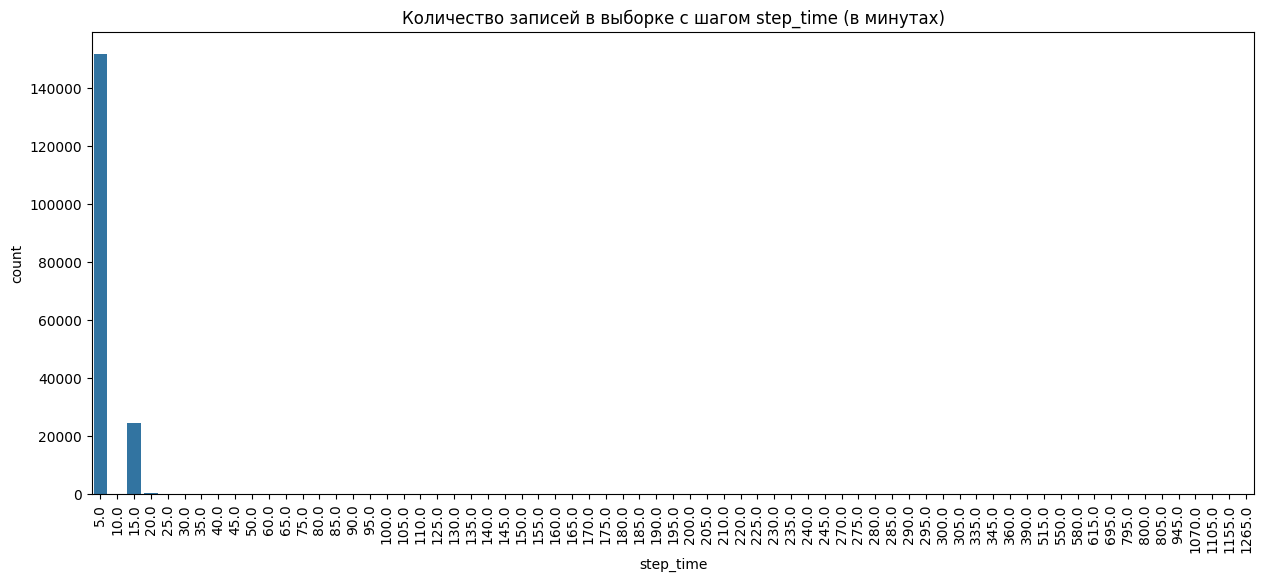

In [50]:
plt.figure(figsize=(15, 6))
plt.title('Количество записей в выборке с шагом step_time (в минутах)')
sns.countplot(x=train_with_basic_features['step_time'])
plt.xticks(rotation=90);

In [51]:
train_with_basic_features['step_time'].value_counts().head(12)

,count
step_time,
5.0,151756
15.0,24527
20.0,403
10.0,121
30.0,33
125.0,12
140.0,10
45.0,8
135.0,7


In [52]:
# статистика step_time по пациентам
train_with_basic_features.groupby('p_num', observed=False).step_time.describe()

,count,unique,top,freq
p_num,,,,
p01,8458.0,20.0,15.0,8223.0
p02,25871.0,12.0,5.0,25855.0
p03,26027.0,9.0,5.0,26013.0
p04,24685.0,10.0,5.0,24638.0
p05,8287.0,36.0,15.0,8080.0
p06,8382.0,26.0,15.0,8218.0
p10,25453.0,12.0,5.0,25431.0
p11,24554.0,15.0,5.0,24540.0
p12,25298.0,16.0,5.0,25279.0


In [53]:
# количество записей с 5 минутным интервалом для каждого пациента
train_with_basic_features[train_with_basic_features.step_time == 5].groupby('p_num', observed=False).step_time.count()

,step_time
p_num,
p01,0
p02,25855
p03,26013
p04,24638
p05,0
p06,0
p10,25431
p11,24540
p12,25279


In [54]:
# количество записей с 15 минутным интервалом для каждого пациента
train_with_basic_features[train_with_basic_features.step_time == 15].groupby('p_num', observed=False).step_time.count()

,step_time
p_num,
p01,8223
p02,1
p03,0
p04,4
p05,8080
p06,8218
p10,0
p11,1
p12,0


 ### Добавление нового столбца 'time_in_minute' - общее количество минут, прошедших с начала текущего дня

In [55]:
#  новый столбец 'time_in_minute' отражает общее количество минут, прошедших с начала текущего дня
train_data['time_in_minute'] = train_data['time'].dt.minute + train_data['time'].dt.hour * 60

### связь между уровнями глюкозы на разных временных точках

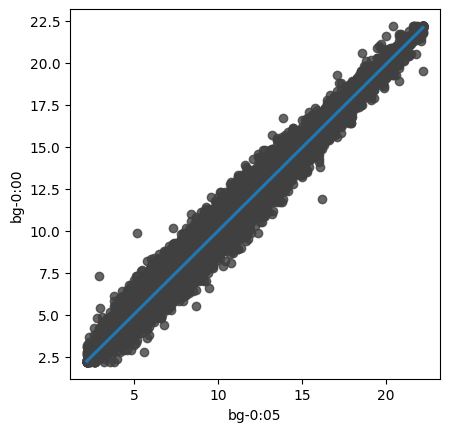

In [56]:
_, ax = plt.subplots()
ax = sns.regplot(x='bg-0:05', y='bg-0:00', data=train_data, scatter_kws=dict(color='.25'))
ax.set_aspect('equal')

### сводная таблица для анализа зависимостей между разными показателями («p_num») в разные моменты времени («time»).

In [57]:
train_data.time = train_with_basic_features.time

In [58]:
# сводная таблица для анализа зависимостей между разными показателями («p_num») в разные моменты времени («time»).
pivot_df = train_data.pivot(index='time', columns='p_num', values='bg-0:00')
pivot_df

p_num,p01,p02,p03,p04,p05,p06,p10,p11,p12
time,,,,,,,,,
1900-01-01 06:05:00,NaN,6.7,7.6,6.7,3.6,NaN,5.1,9.3,NaN
1900-01-01 06:10:00,15.1,6.5,7.3,6.6,NaN,NaN,5.4,9.2,NaN
1900-01-01 06:15:00,NaN,6.5,7.2,6.2,NaN,NaN,5.2,9.1,NaN
1900-01-01 06:20:00,NaN,6.5,7.2,6.0,3.7,NaN,5.1,9.1,NaN
1900-01-01 06:25:00,14.4,6.5,7.1,5.7,NaN,NaN,4.9,9.2,NaN
...,...,...,...,...,...,...,...,...,...
1900-04-02 23:35:00,NaN,11.7,11.9,NaN,5.9,NaN,NaN,NaN,9.8
1900-04-02 23:40:00,NaN,12.4,11.4,NaN,NaN,NaN,NaN,NaN,10.3
1900-04-02 23:45:00,NaN,12.8,10.3,NaN,NaN,NaN,NaN,NaN,10.7


### Активности

In [59]:
# определяем список активностей
with open(dir_path + 'activities.txt', 'r') as file:
    activities = [line[:-1] for line in file]
activities

['Indoor climbing',
 'Run',
 'Strength training',
 'Swim',
 'Bike',
 'Dancing',
 'Stairclimber',
 'Spinning',
 'Walking',
 'HIIT',
 'Outdoor Bike',
 'Walk',
 'Aerobic Workout',
 'Tennis',
 'Workout',
 'Hike',
 'Zumba',
 'Sport',
 'Yoga',
 'Swimming',
 'Weights',
 'Running']

- Indoor climbing — скалолазание в помещении
- Run — бег
- Strength training — силовые тренировки
- Swim — плавание
- Bike — велоспорт/езда на велосипеде
- Dancing — танцы
- Stairclimber — восхождение по лестнице (ступеньковый тренажёр)
- Spinning — спиннинг (групповая тренировка на стационарных велосипедах)
- Walking — ходьба пешком
- HIIT — высокоинтенсивные интервальные тренировки
- Outdoor Bike — велосипедные прогулки на открытом воздухе
- Walk — прогулка пешком
- Aerobic Workout — аэробика
- Tennis — теннис
- Workout — общая физическая тренировка
- Hike — пеший поход, треккинг
- Zumba — зумба (танцевальная фитнес-программа)
- Sport — спорт (общий термин)
- Yoga — йога
- Swimming — плавание
- Weights — упражнения с весами (гантели, штанги)
- Running — бег трусцой, регулярные беговые тренировки

In [60]:
train_data.replace({'Running': 'Run',
                    'Swimming': 'Swim',
                    'Walking': 'Walk',
                    'Weights': 'Strength training',
                    },
                   inplace=True)

In [61]:
to_remove = {'Running', 'Swimming', 'Walking', 'Weights'}  # используем set для ускорения проверки принадлежности

activities = [item for item in activities if item not in to_remove]
activities

['Indoor climbing',
 'Run',
 'Strength training',
 'Swim',
 'Bike',
 'Dancing',
 'Stairclimber',
 'Spinning',
 'HIIT',
 'Outdoor Bike',
 'Walk',
 'Aerobic Workout',
 'Tennis',
 'Workout',
 'Hike',
 'Zumba',
 'Sport',
 'Yoga']

In [62]:
cat_dtype = CategoricalDtype(categories=activities, ordered=False)

In [63]:
# преобразование типов данных в категориальный
activity_columns = train_data.select_dtypes(include=['object']).columns
train_data[activity_columns] = train_data[activity_columns].astype(cat_dtype)

In [64]:
train_data['activity-1:00'].cat.categories

Index(['Indoor climbing', 'Run', 'Strength training', 'Swim', 'Bike',
       'Dancing', 'Stairclimber', 'Spinning', 'HIIT', 'Outdoor Bike', 'Walk',
       'Aerobic Workout', 'Tennis', 'Workout', 'Hike', 'Zumba', 'Sport',
       'Yoga'],
      dtype='object')

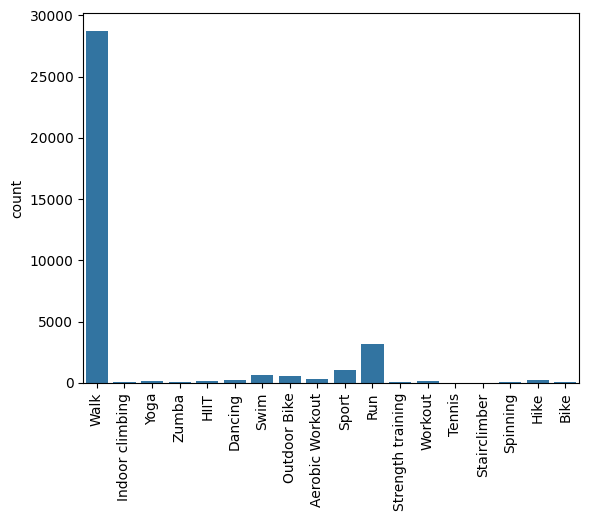

In [65]:
sns.countplot(x=train_data.loc[:,'activity-1:00':'activity-0:00'].values.ravel())
plt.xticks(rotation=90);

In [66]:
pd.Series(train_data.loc[:,'activity-1:00':'activity-0:00'].values.ravel()).value_counts()

,count
Walk,28739
Run,3144
Sport,1061
Swim,614
Outdoor Bike,566
Aerobic Workout,308
Hike,260
Dancing,187
HIIT,134
Workout,127


In [67]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 177024 entries, p01_0 to p12_25298
Columns: 508 entries, p_num to time_in_minute
dtypes: category(73), datetime64[ns](1), float64(433), int32(1)
memory usage: 604.6+ MB


### Исследуем bg-0:00

In [68]:
train_bg = train_data[['time', 'bg-0:00', 'p_num']].copy()
train_bg

,time,bg-0:00,p_num
id,,,
p01_0,1900-01-01 06:10:00,15.1,p01
p01_1,1900-01-01 06:25:00,14.4,p01
p01_2,1900-01-01 06:40:00,13.9,p01
p01_3,1900-01-01 06:55:00,13.8,p01
p01_4,1900-01-01 07:10:00,13.4,p01
...,...,...,...
p12_25294,1900-04-02 23:35:00,9.8,p12
p12_25295,1900-04-02 23:40:00,10.3,p12
p12_25296,1900-04-02 23:45:00,10.7,p12


Text(0, 0.5, 'Плотность вероятности')

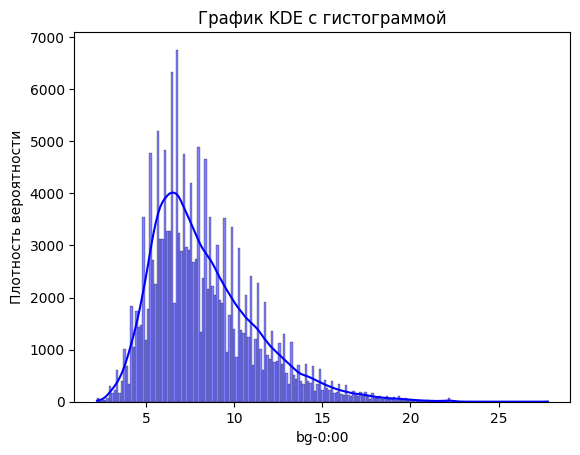

In [69]:
sns.histplot(train_bg['bg-0:00'], color='b', kde=True)
plt.title('График KDE с гистограммой')
plt.ylabel('Плотность вероятности')

Распределение похоже на нормальное, но слегка скошено вправо.

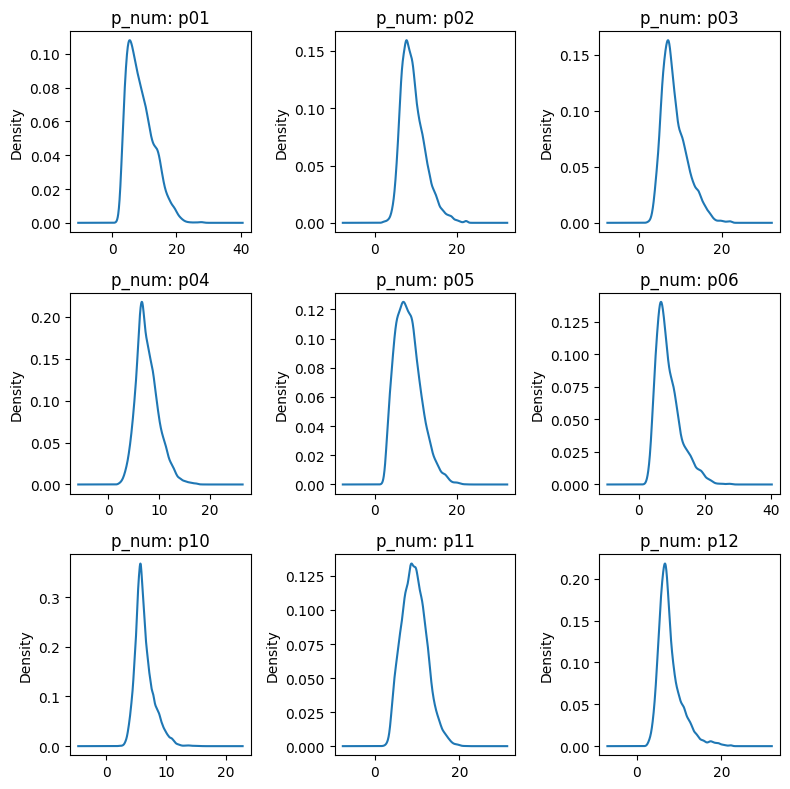

In [70]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(8, 8))

# Группируем данные по 'p_num' и строим KDE на отдельных подграфиках
for i, (p_num, group) in enumerate(train_bg.groupby('p_num', observed=True)):
    ax = axes.flatten()[i]
    group['bg-0:00'].plot(kind='kde', ax=ax, title=f'p_num: {p_num}')

plt.tight_layout()
plt.show()

<Axes: xlabel='bg-0:00', ylabel='Density'>

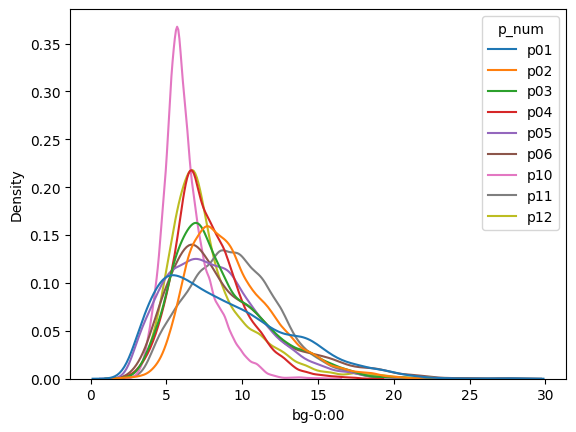

In [71]:
sns.kdeplot(data=train_bg, x='bg-0:00', hue='p_num', common_norm=False)

Text(0.5, 1.0, 'boxplot уровень глюкозы')

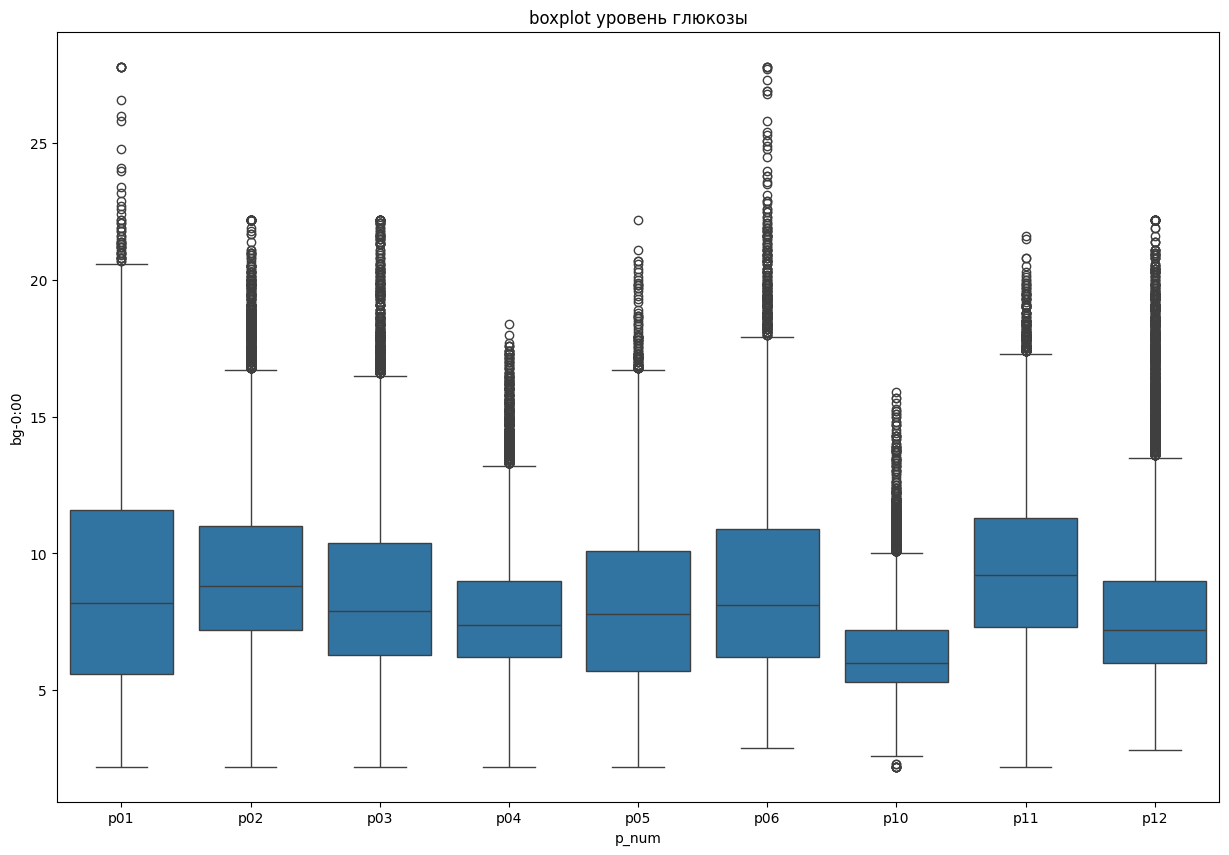

In [72]:
plt.figure(figsize=(15, 10))
sns.boxplot(data=train_bg, y='bg-0:00', x='p_num')
plt.title('boxplot уровень глюкозы')

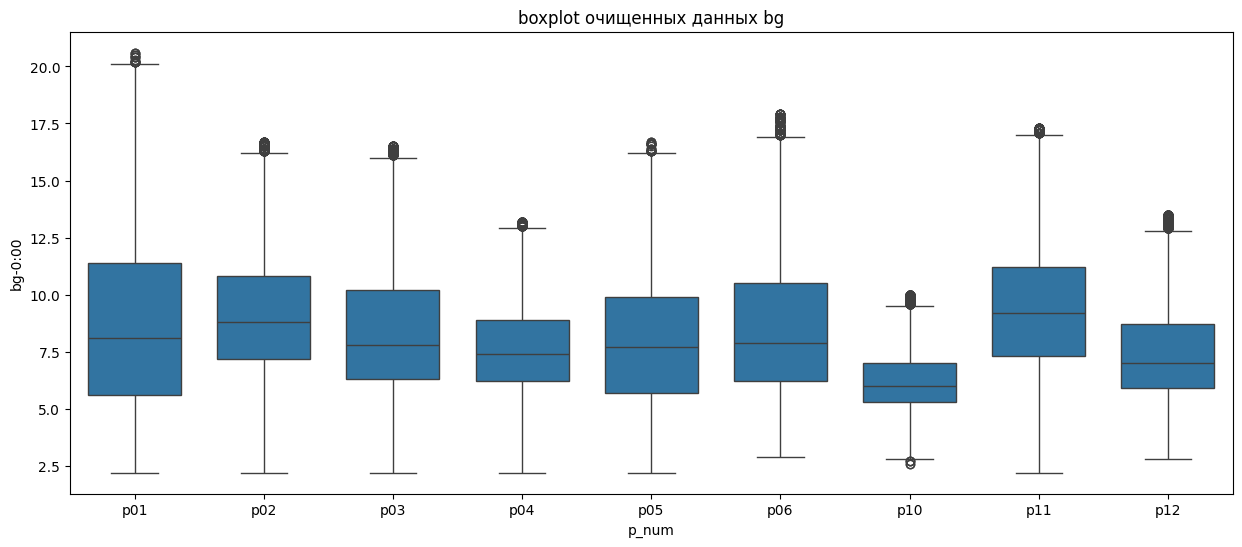

In [73]:
# Функция для удаления выбросов
def remove_outliers(group):
    Q1 = group['bg-0:00'].quantile(0.25)
    Q3 = group['bg-0:00'].quantile(0.75)
    IQR = Q3 - Q1
    return group[~((group['bg-0:00'] < (Q1 - 1.5 * IQR)) | (group['bg-0:00'] > (Q3 + 1.5 * IQR)))]

train_insulin_cleaned = train_with_basic_features.groupby('p_num', observed=False).apply(remove_outliers, include_groups=False)

# Построение боксплота для очищенных данных
plt.figure(figsize=(15, 6))
sns.boxplot(data=train_insulin_cleaned, y='bg-0:00', x='p_num', gap=.1)
plt.title('boxplot очищенных данных bg')
plt.show()

In [74]:
def cyclical_plot(X, y, period, freq, ax=None):
    """
    Построение циклического графика для визуализации периодичных данных.

    Эта функция создает линейный график, где каждая линия представляет собой отдельную группу данных,
    соответствующую уникальному значению указанного периода. График позволяет легко увидеть изменения
    переменной `y` в зависимости от частоты `freq` для разных групп, определенных периодом `period`.

    Parameters:
    -----------
    X : pandas.DataFrame
        Таблица данных, содержащая столбцы для периодичности, частоты и целевого показателя.

    y : str
        Имя столбца в таблице данных `X`, значения которого отображаются на оси Y.

    period : str
        Имя столбца в таблице данных `X`, задающее группы периодов (например, месяцы).

    freq : str
        Имя столбца в таблице данных `X`, задающее частоту внутри каждого периода (например, дни месяца).

    ax : matplotlib.axes.Axes, optional
        Объект осей Matplotlib, на котором строится график. Если None, создаются новые оси.
    Returns:
        --------
        matplotlib.axes.Axes
            Объект осей с построенным графиком, готовый для дальнейшего оформления или вывода.
    """

    if ax is None:
        _, ax = plt.subplots(figsize=(18, 10))
    palette = sns.color_palette("husl", n_colors=X[period].nunique(),)
    ax = sns.lineplot(
        x=freq,
        y=y,
        hue=period,
        data=X,
        errorbar=('ci', False),
        ax=ax,
        palette=palette,
        legend=False,
    )
    ax.set_title(f"Cyclical Plot ({period}/{freq})")
    for line, name in zip(ax.lines, X[period].unique()):
        y_ = line.get_ydata()[-1]
        ax.annotate(
            name,
            xy=(1, y_),
            xytext=(6, 0),
            color=line.get_color(),
            xycoords=ax.get_yaxis_transform(),
            textcoords="offset points",
            size=10,
            va="center",
        )
    return ax

In [75]:
train_day_number = train_bg.set_index(['time']).copy()
# Определяем первый день
first_day = train_day_number.index.min()

# Расчет разницы в днях
days_since_first = (train_day_number.index - first_day).days

# Добавляем новый столбец "day_number"
train_day_number["day_number"] = days_since_first + 1  # прибавляем единицу, чтобы начать нумерацию с 1-го дня
train_day_number["hour"] = train_day_number.index.hour
train_day_number

,bg-0:00,p_num,day_number,hour
time,,,,
1900-01-01 06:10:00,15.1,p01,1,6
1900-01-01 06:25:00,14.4,p01,1,6
1900-01-01 06:40:00,13.9,p01,1,6
1900-01-01 06:55:00,13.8,p01,1,6
1900-01-01 07:10:00,13.4,p01,1,7
...,...,...,...,...
1900-04-02 23:35:00,9.8,p12,92,23
1900-04-02 23:40:00,10.3,p12,92,23
1900-04-02 23:45:00,10.7,p12,92,23


In [76]:
train_week_number = train_bg.set_index(['time']).copy()
train_week_number["week"] = train_week_number.index.isocalendar().week
train_week_number["day_of_week"] = train_week_number.index.dayofweek
train_week_number

,bg-0:00,p_num,week,day_of_week
time,,,,
1900-01-01 06:10:00,15.1,p01,1,0
1900-01-01 06:25:00,14.4,p01,1,0
1900-01-01 06:40:00,13.9,p01,1,0
1900-01-01 06:55:00,13.8,p01,1,0
1900-01-01 07:10:00,13.4,p01,1,0
...,...,...,...,...
1900-04-02 23:35:00,9.8,p12,14,0
1900-04-02 23:40:00,10.3,p12,14,0
1900-04-02 23:45:00,10.7,p12,14,0


In [77]:
train_week_number.day_of_week.unique()

array([0, 1, 2, 3, 4, 5, 6], dtype=int32)

<Axes: title={'center': 'Cyclical Plot (week/day_of_week)'}, xlabel='day_of_week', ylabel='bg-0:00'>

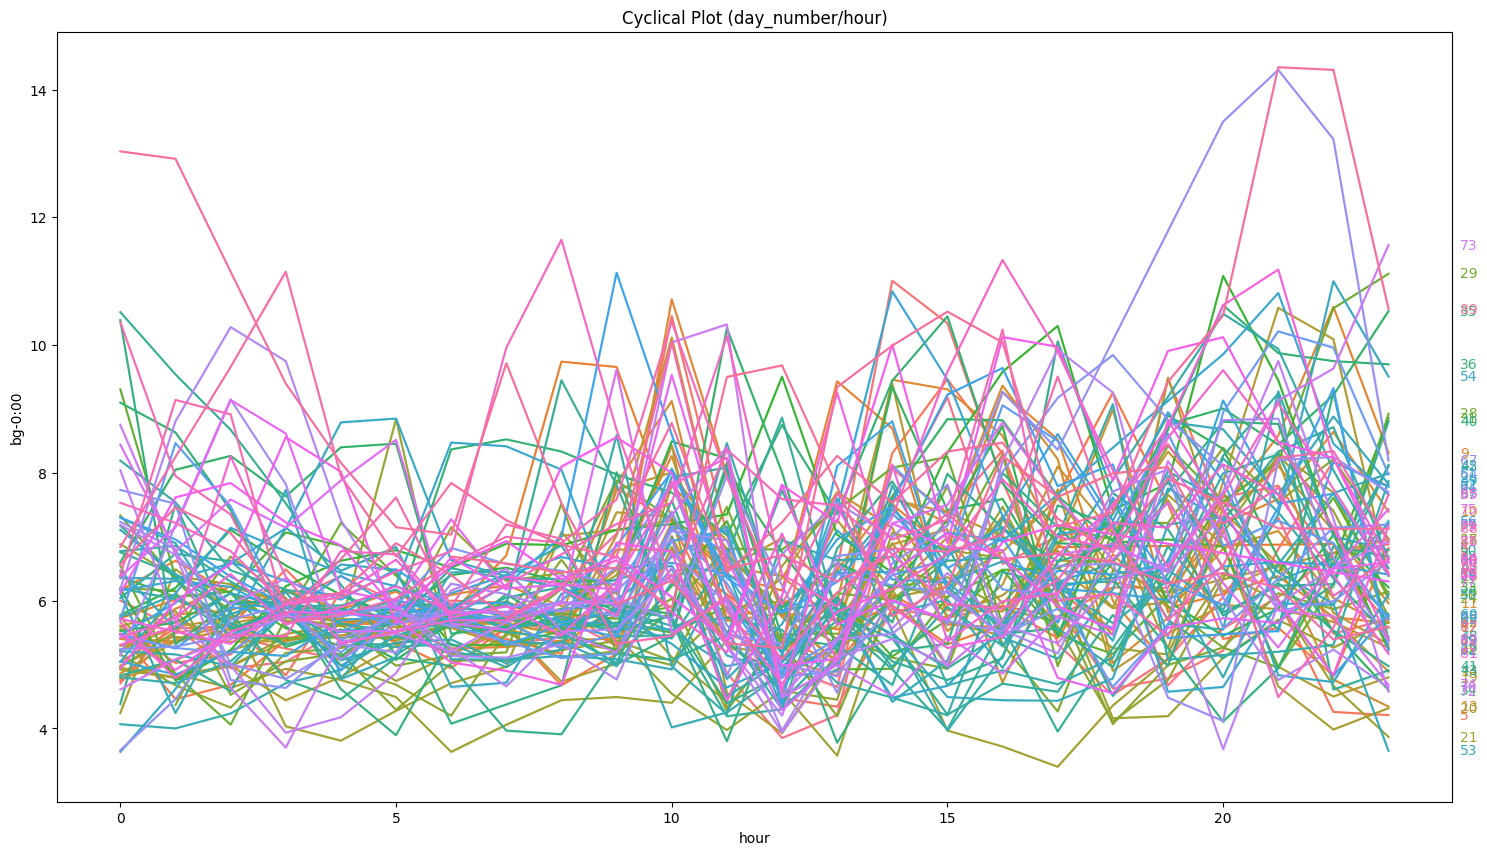

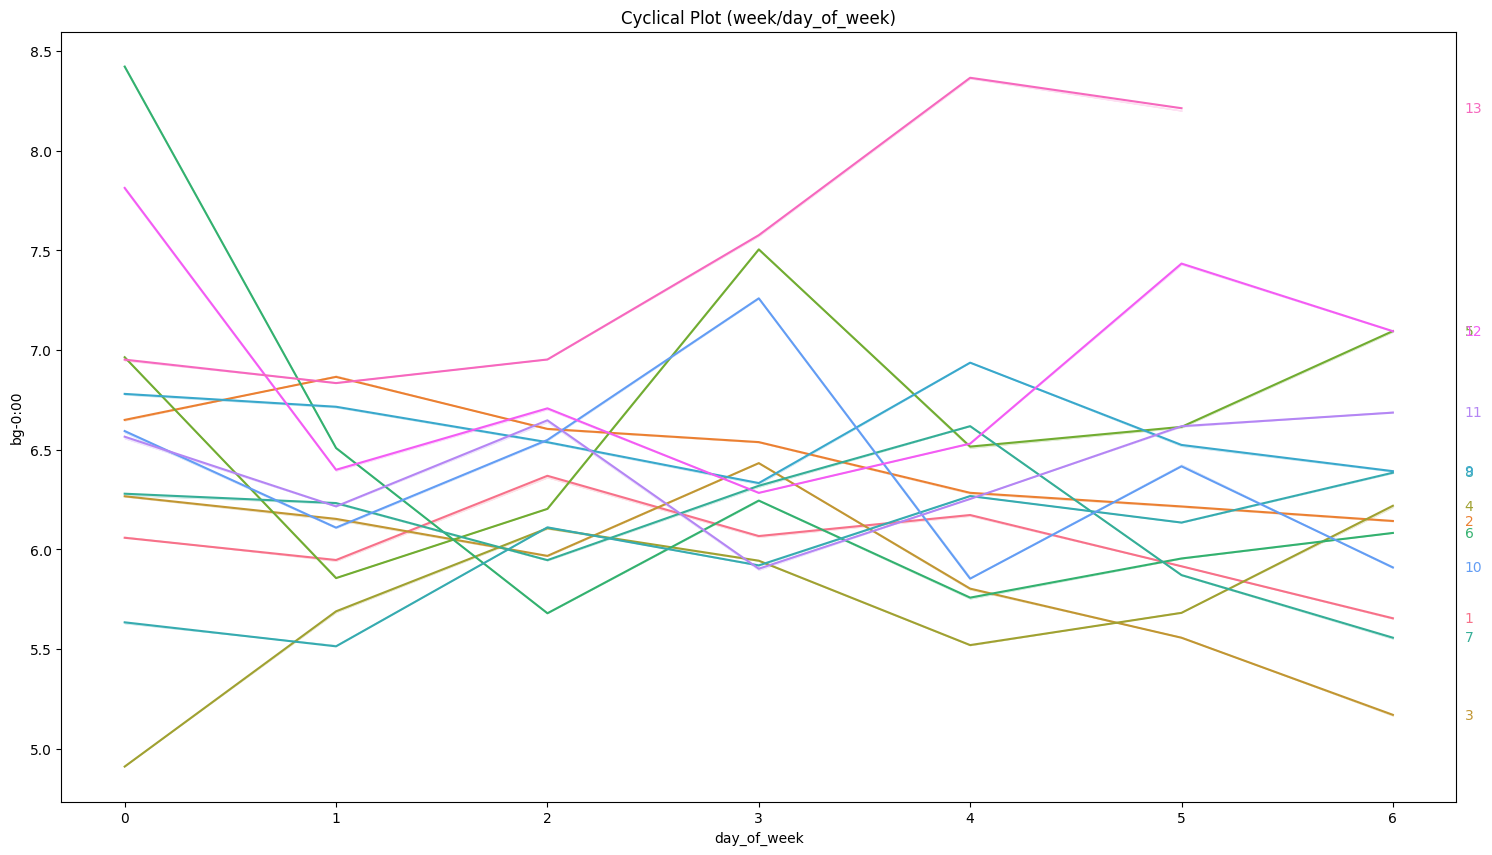

In [78]:
train_day_number_p10 = train_day_number.groupby('p_num', observed=True).get_group('p10')
train_week_number_p10 = train_week_number.groupby('p_num', observed=True).get_group('p10')

cyclical_plot(train_day_number_p10, y='bg-0:00', period='day_number', freq='hour')
cyclical_plot(train_week_number_p10, y='bg-0:00', period='week', freq='day_of_week')

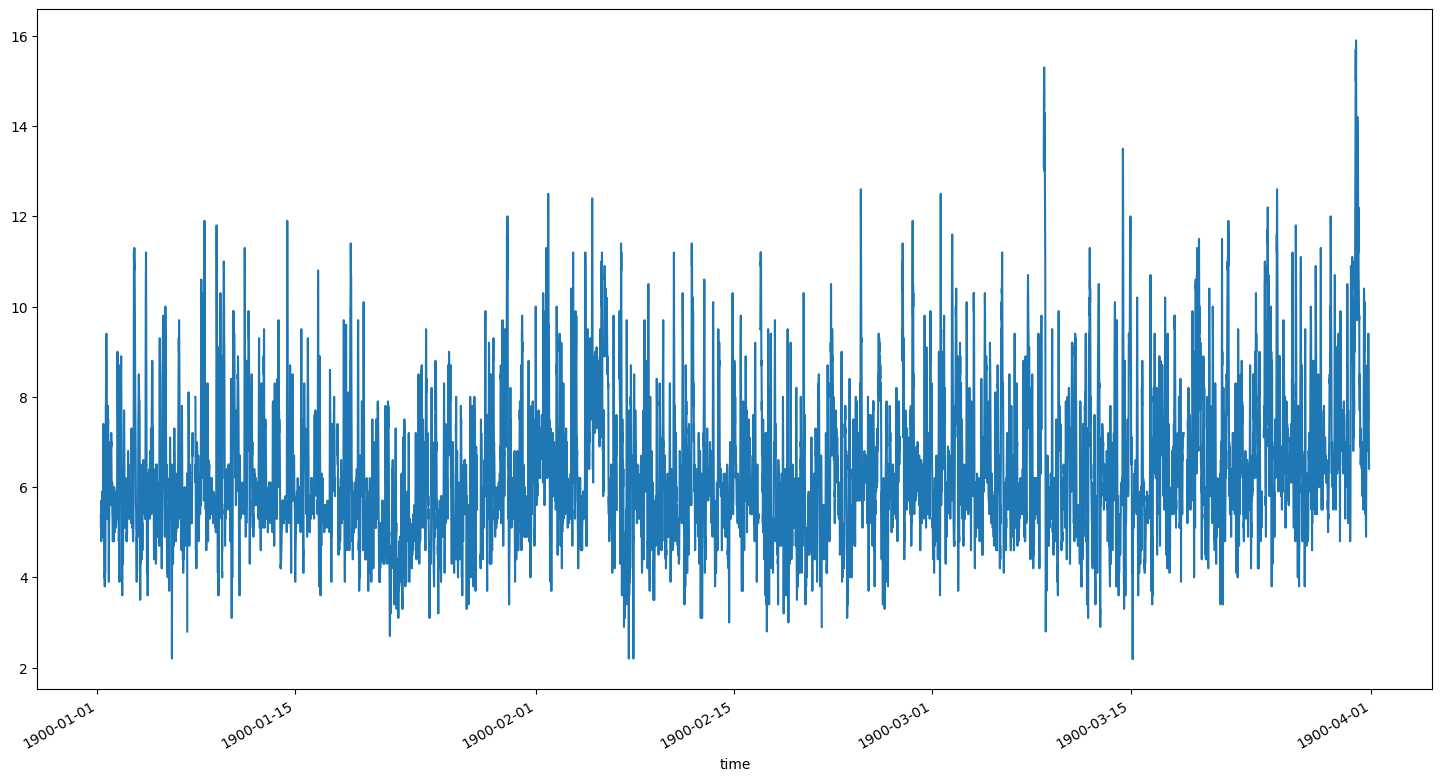

In [79]:
plt.subplots(figsize=(18, 10))
train_day_number_p10['bg-0:00'].plot();

<Axes: title={'center': 'Cyclical Plot (week/day_of_week)'}, xlabel='day_of_week', ylabel='bg-0:00'>

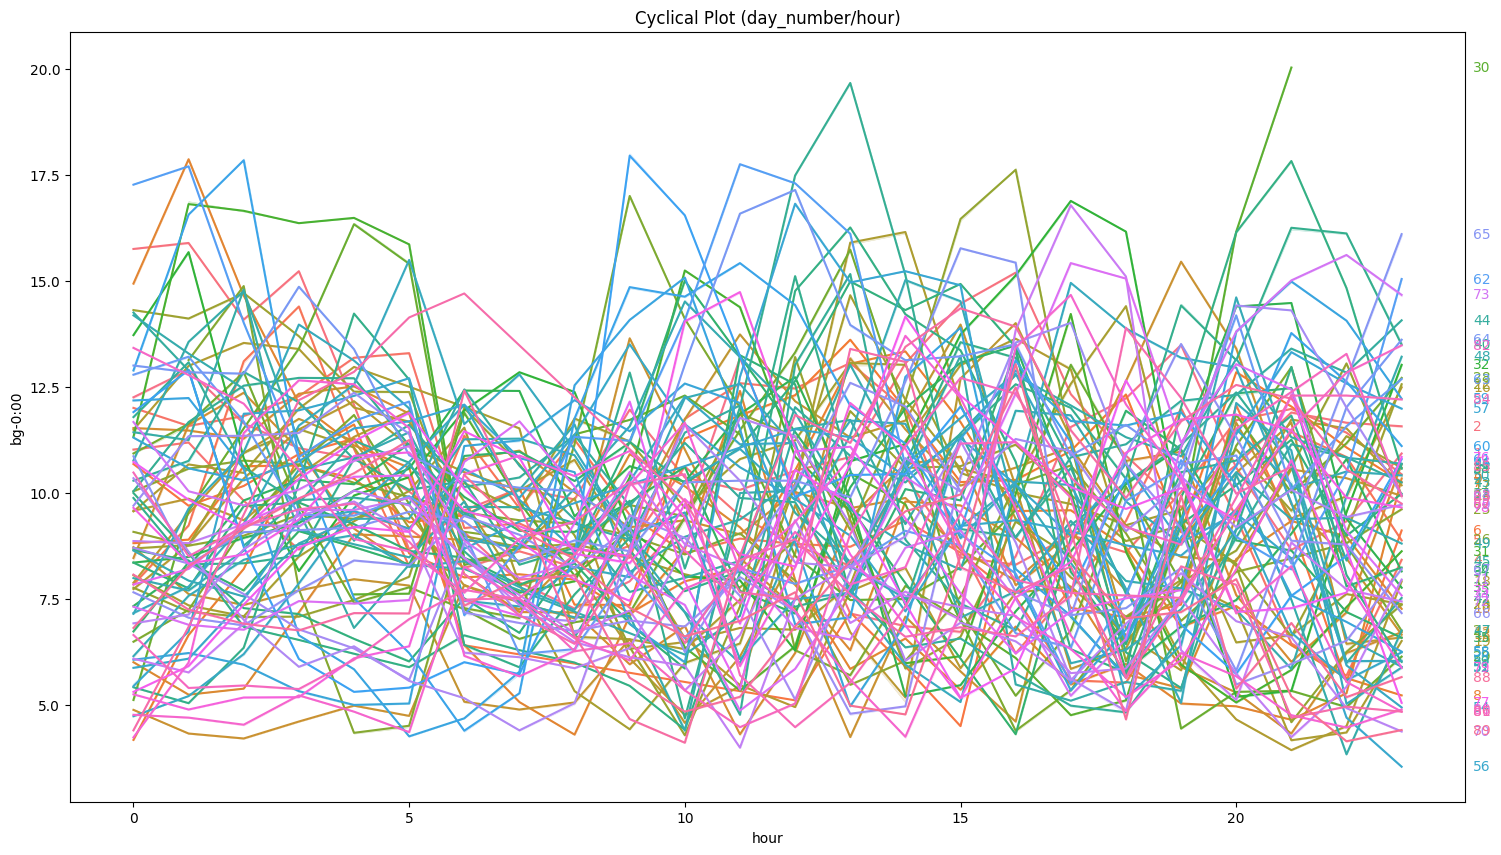

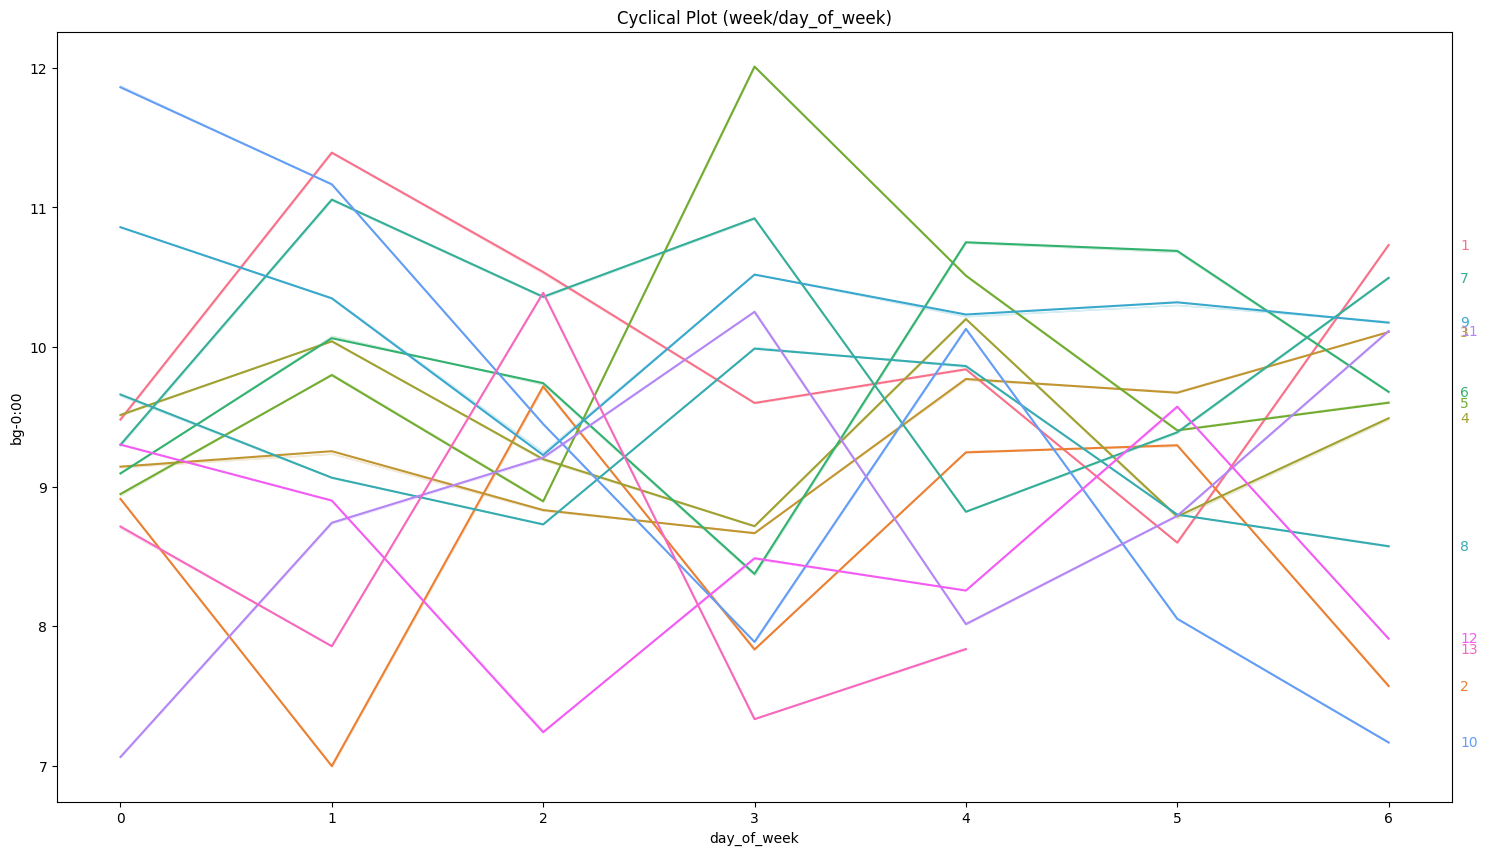

In [80]:
train_day_number_p11 = train_day_number.groupby('p_num', observed=True).get_group('p11')
train_week_number_p11 = train_week_number.groupby('p_num', observed=True).get_group('p11')

cyclical_plot(train_day_number_p11, y='bg-0:00', period='day_number', freq='hour')
cyclical_plot(train_week_number_p11, y='bg-0:00', period='week', freq='day_of_week')

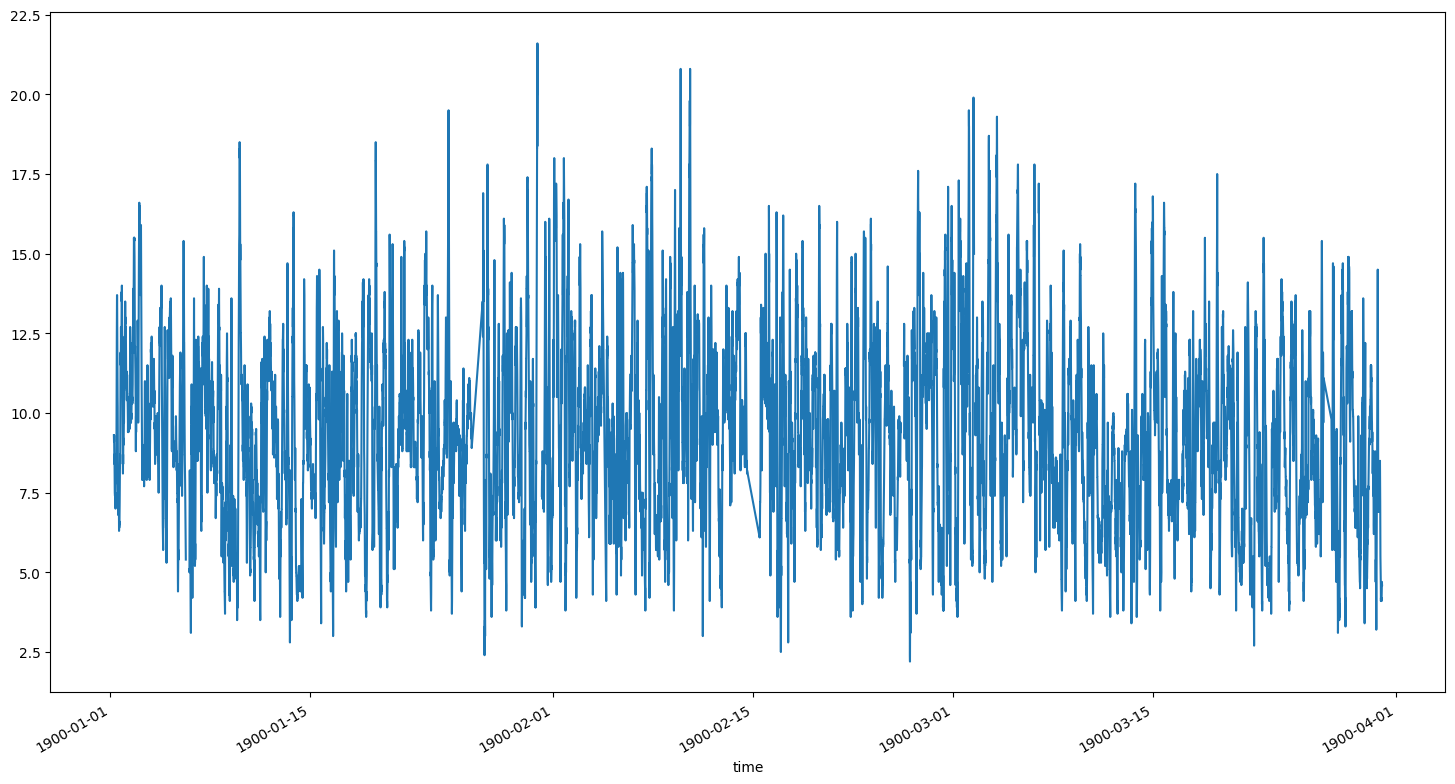

In [81]:
plt.subplots(figsize=(18, 10))
train_day_number_p11['bg-0:00'].plot();

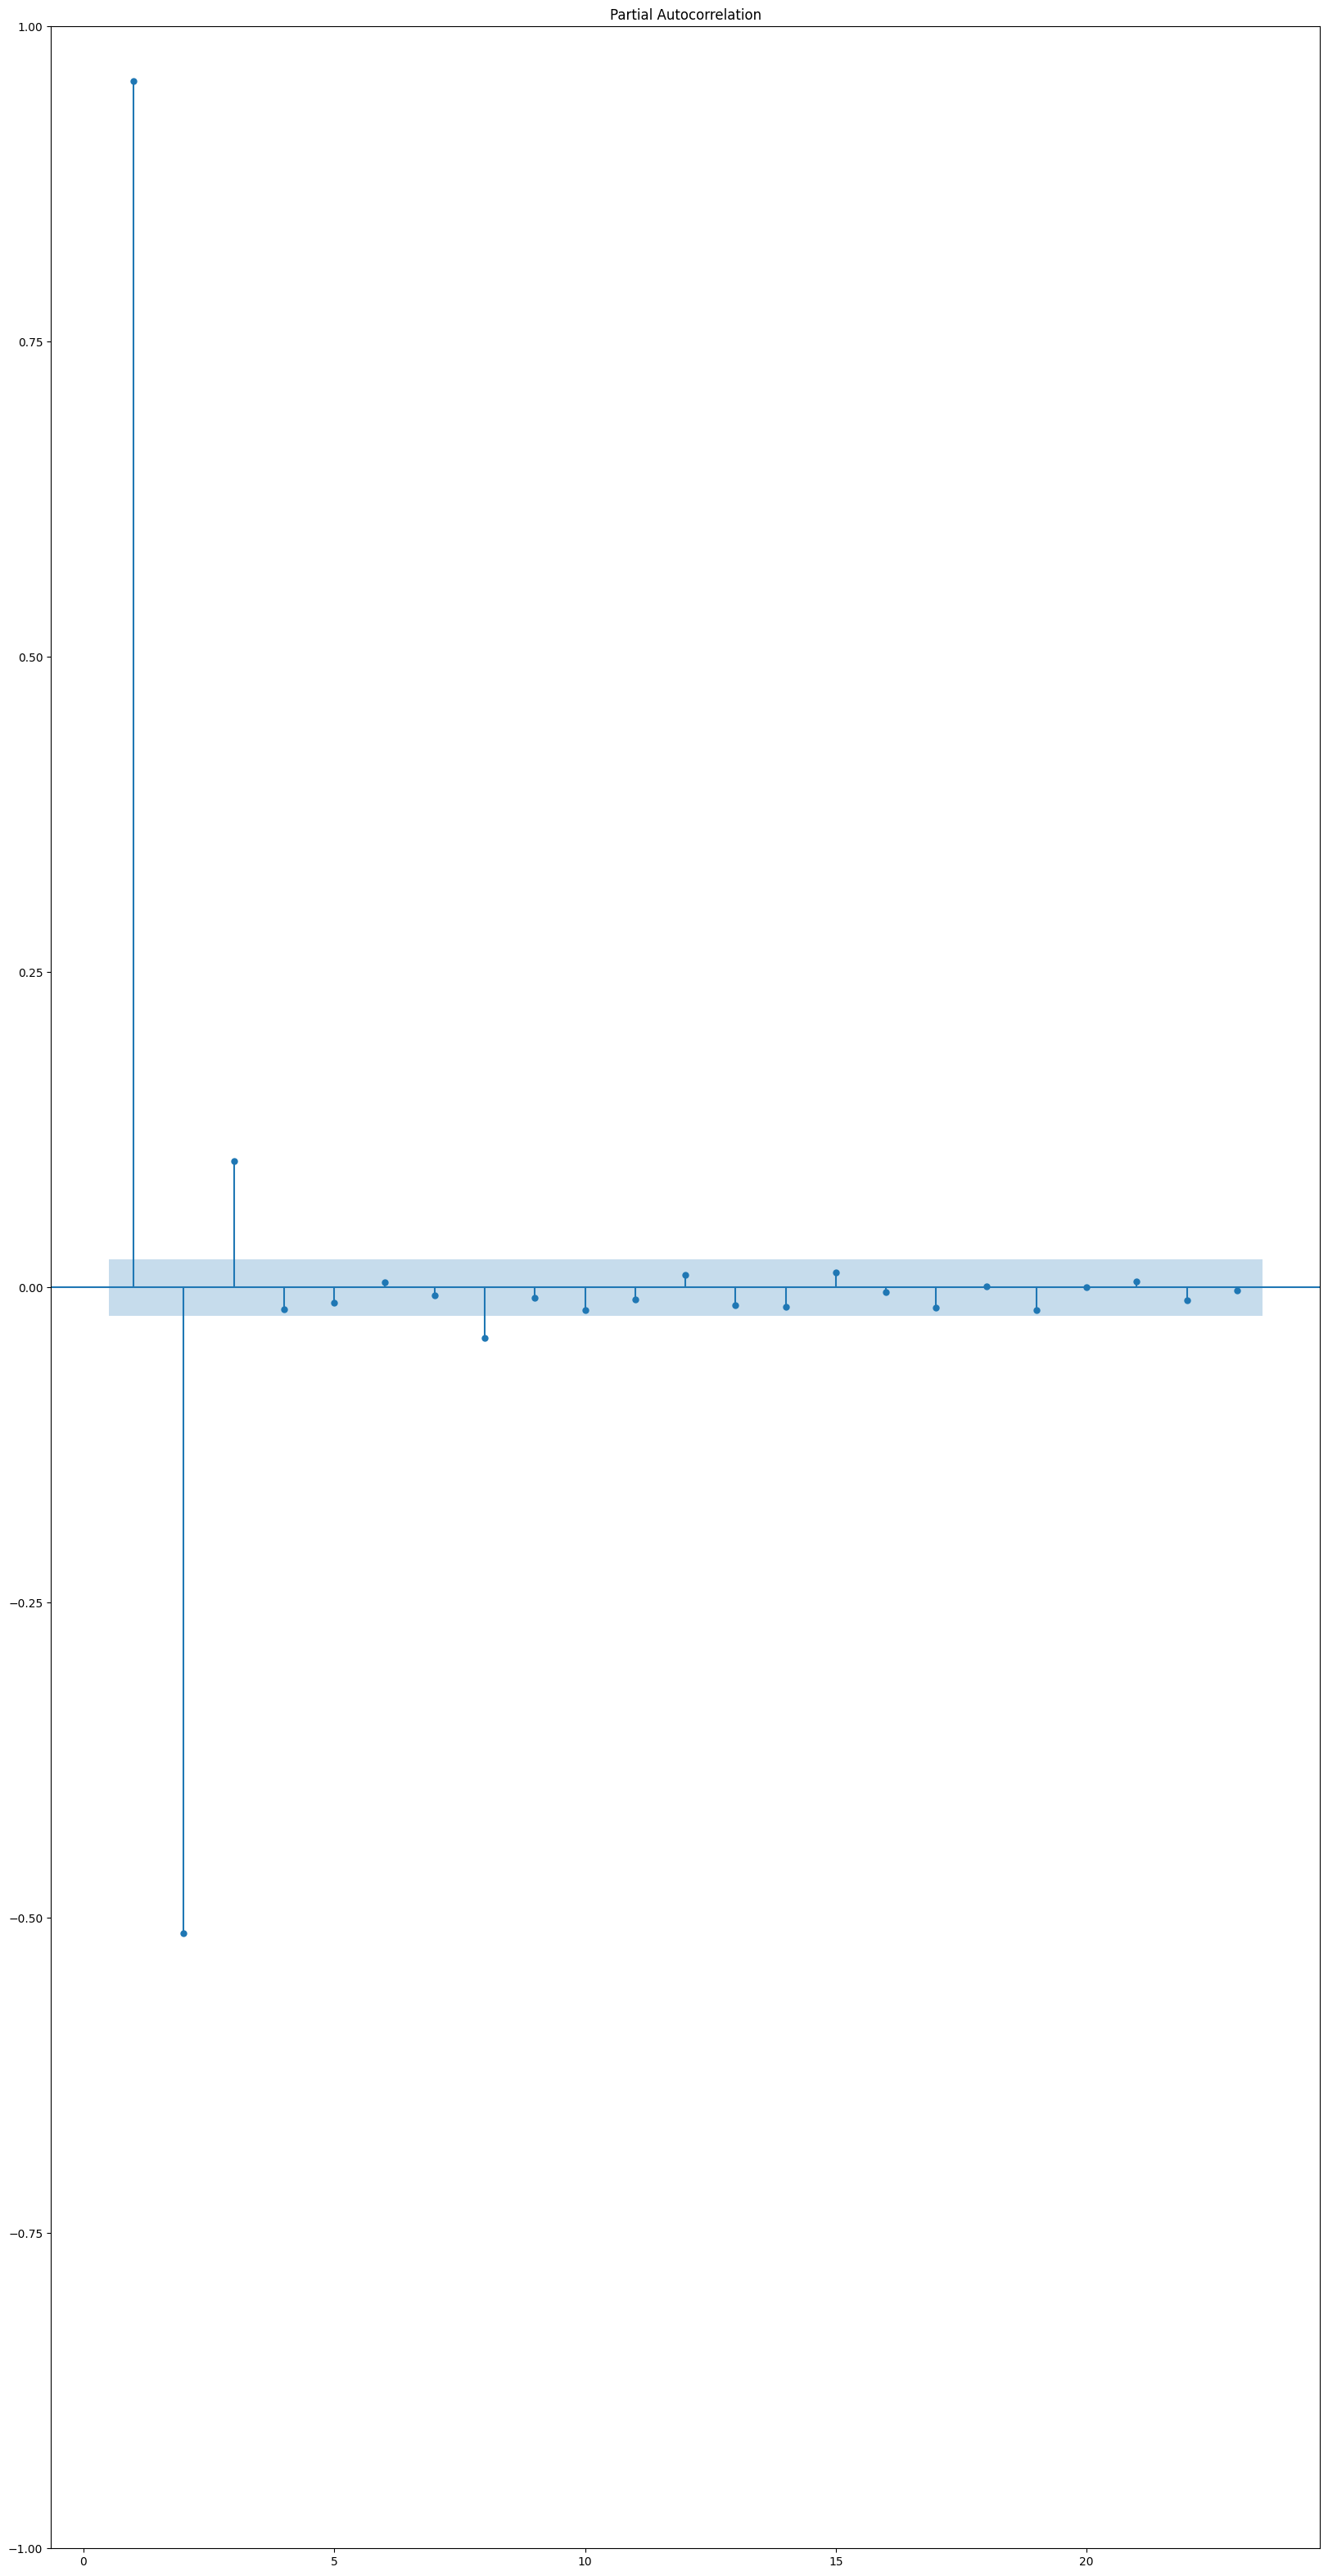

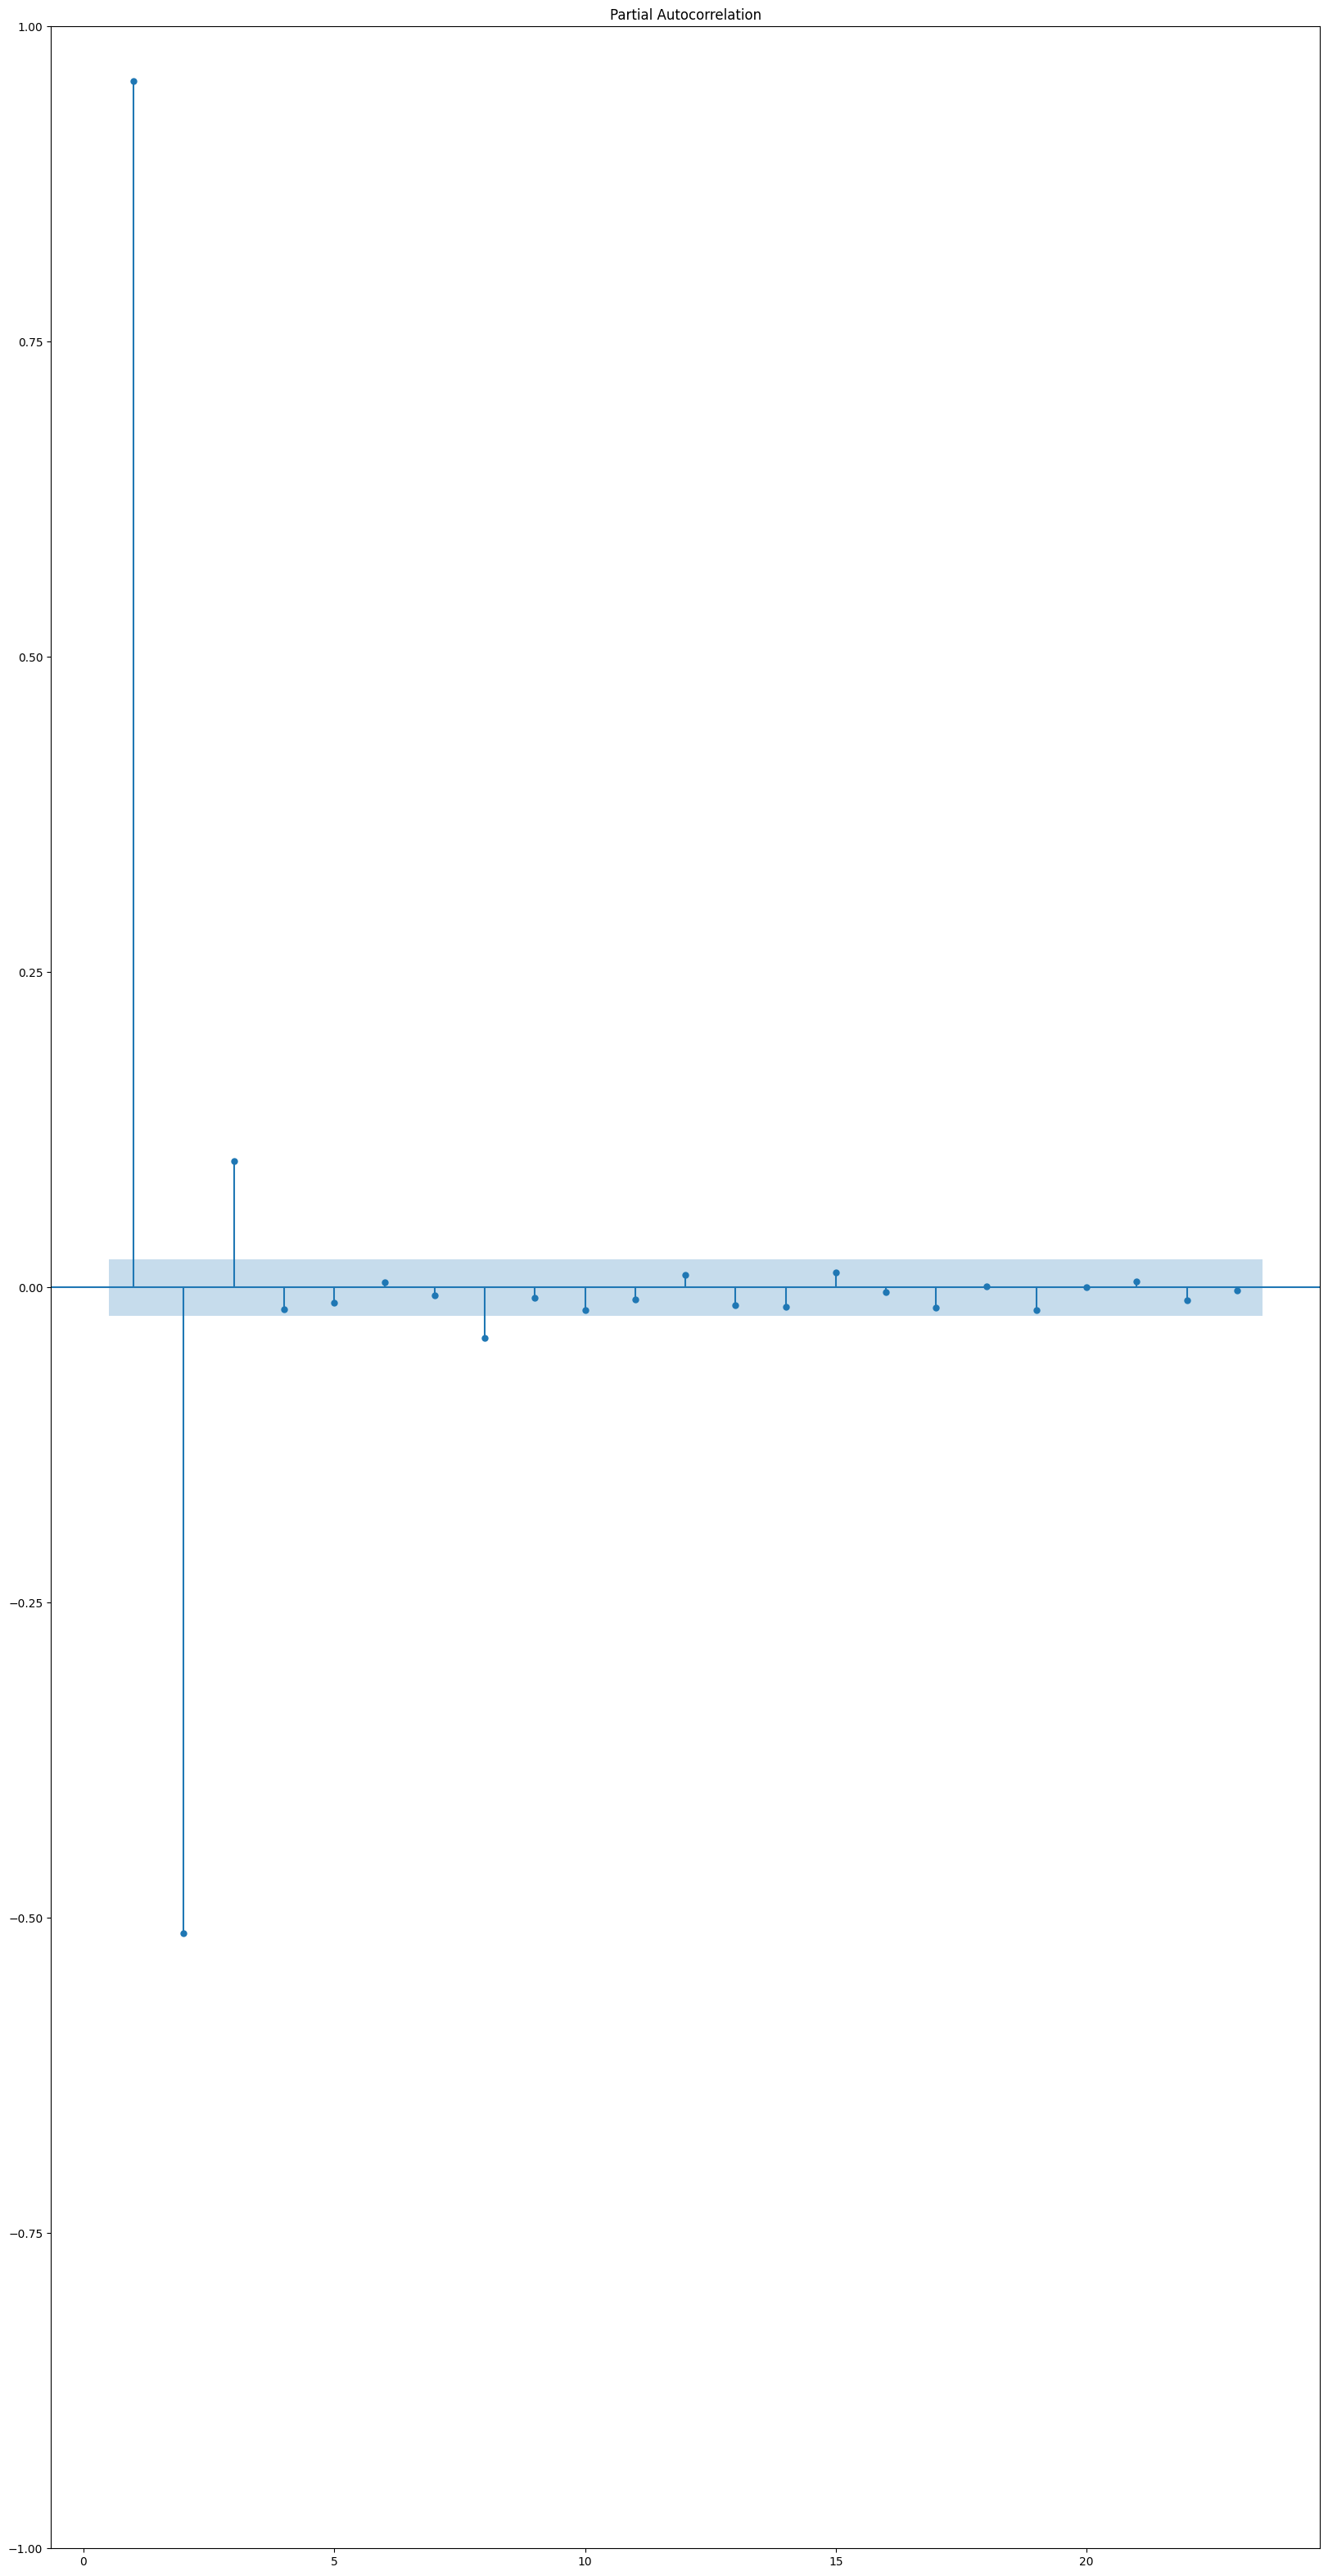

In [82]:
from statsmodels.graphics.tsaplots import plot_pacf

train_day_number_p01 = train_day_number.groupby('p_num', observed=True).get_group('p01')
fig, ax = plt.subplots(figsize=(20, 40))
plot_pacf(train_day_number_p01['bg-0:00'].dropna(), ax=ax, lags=23, zero=False)

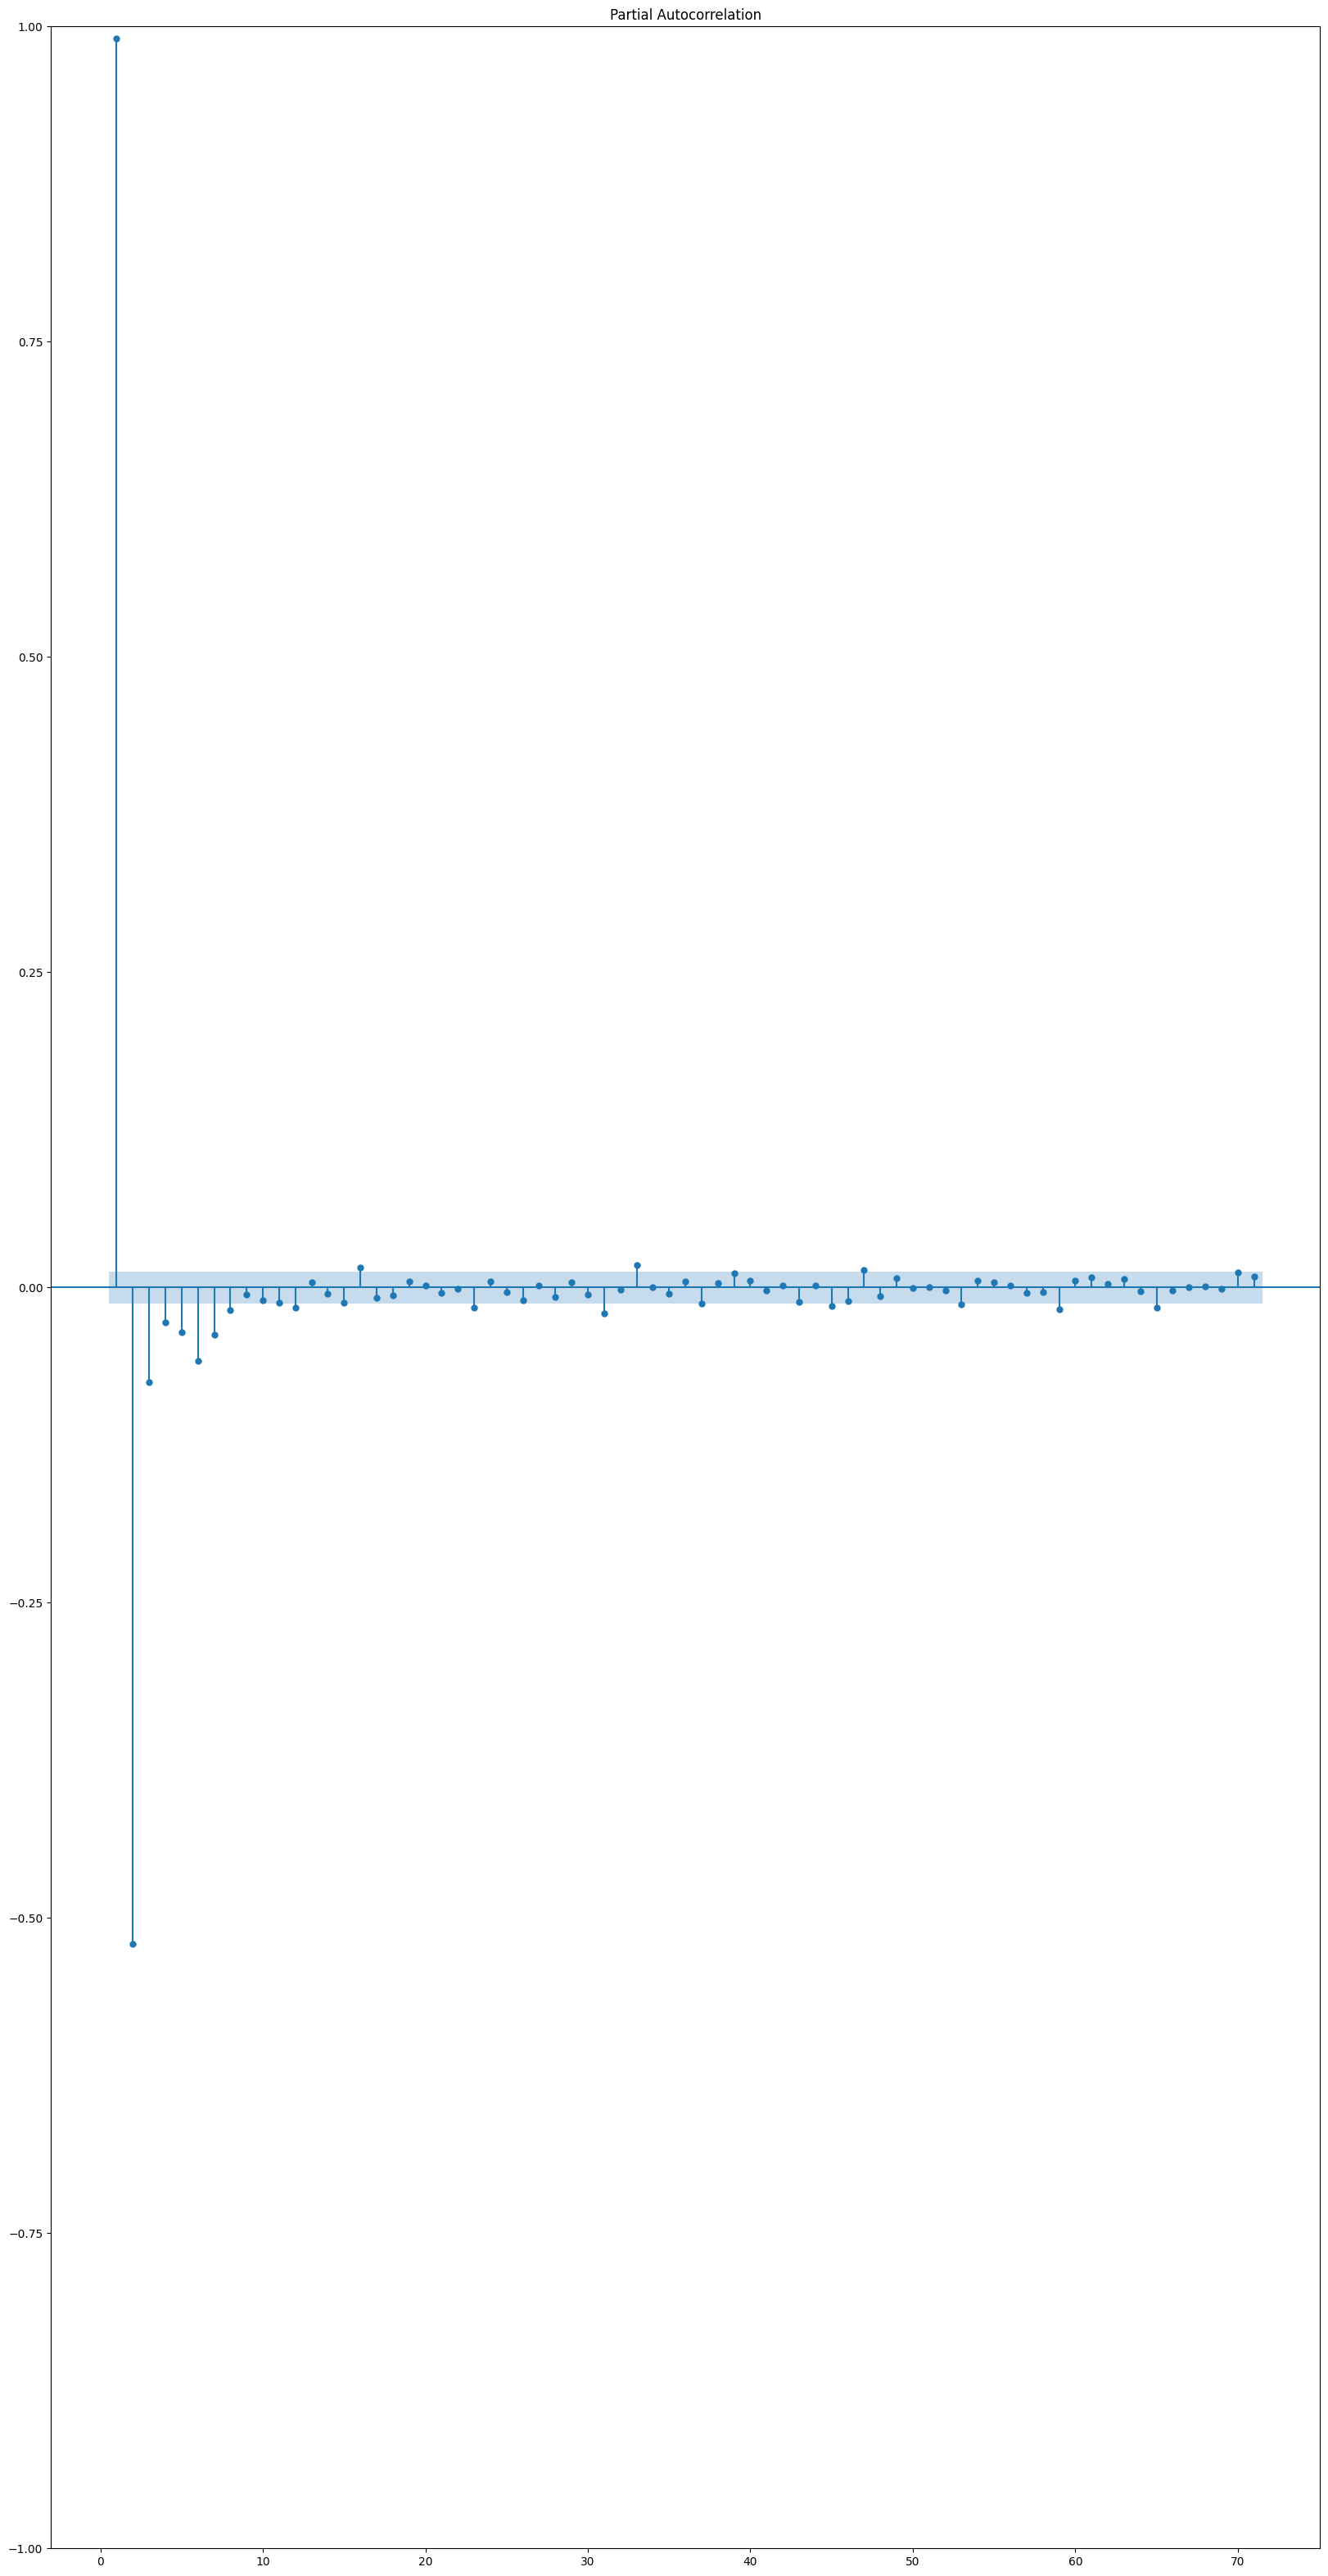

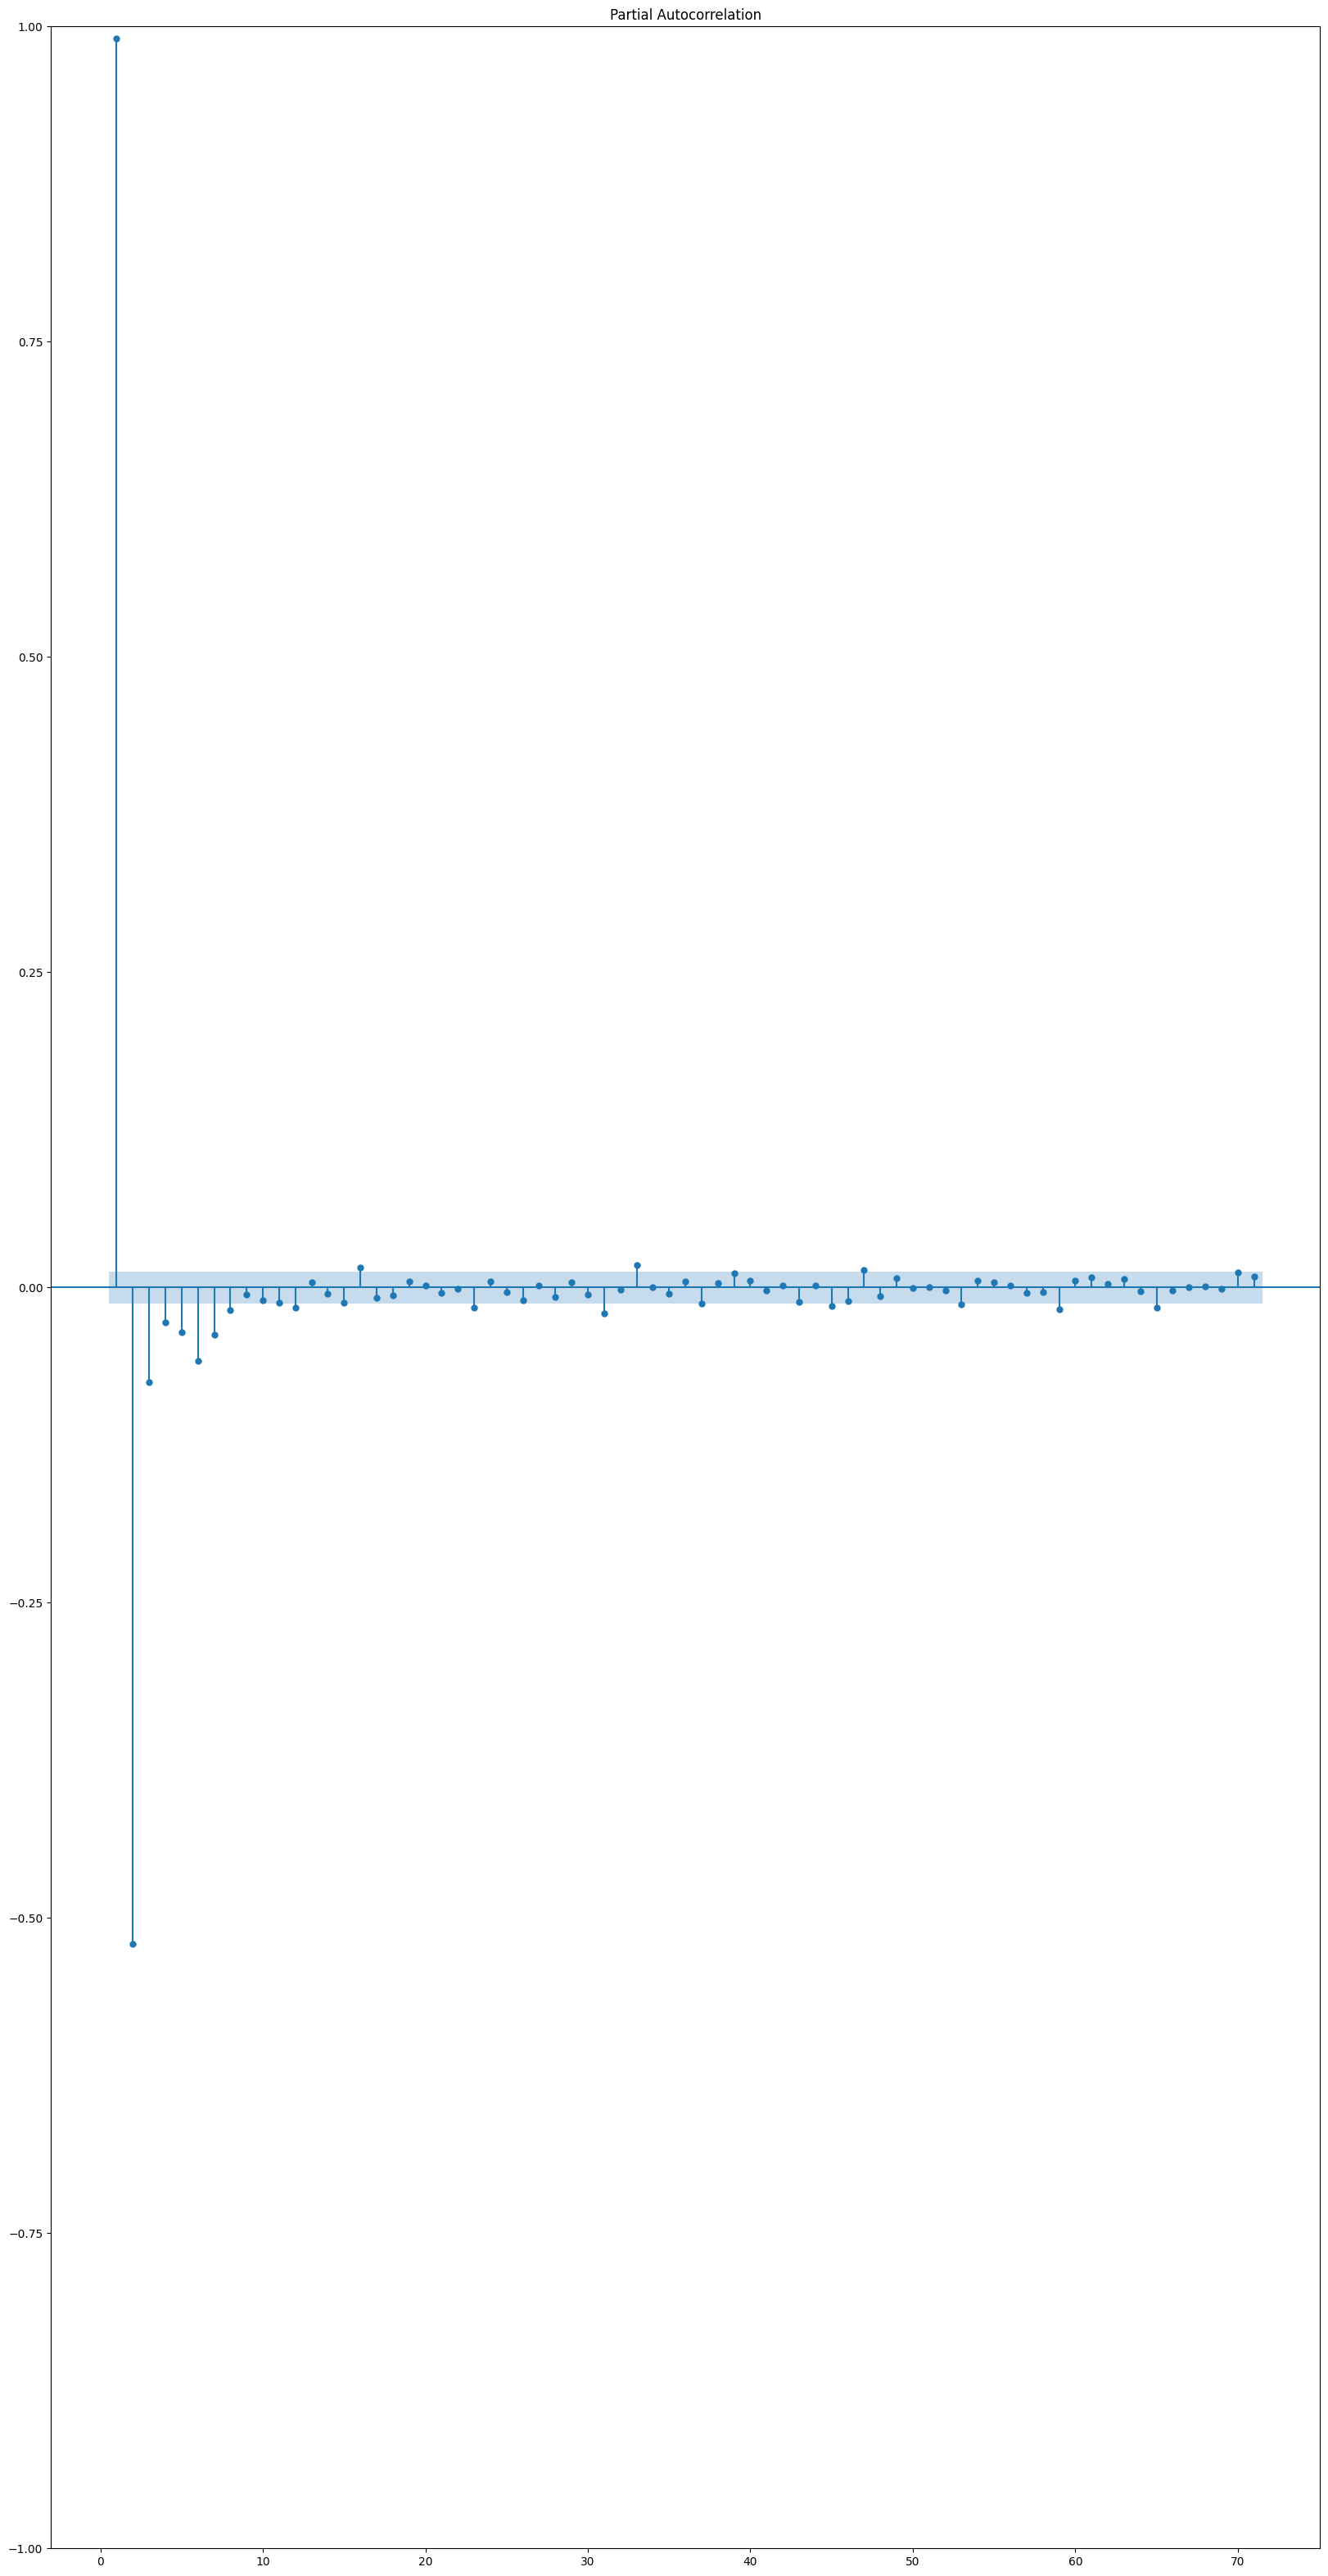

In [83]:
fig, ax = plt.subplots(figsize=(20, 40))
plot_pacf(train_day_number_p11['bg-0:00'].dropna(), ax=ax, lags=71, zero=False)